In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(palette="colorblind", style='whitegrid', font_scale=1.25)


In [2]:
METRIC_MAP = {
    "Demographic_Parity": "Dem_Parity",
    "Equal_Opportunity": "Eq_Opp", 
    "Predictive_Equality": "Pred_Eq",
}

In [3]:

result_files = [os.path.join(dp, f) for dp, _, fn in os.walk(os.path.expanduser("fairness_trials")) for f in fn if f.endswith(".csv")]

all_results = []
for rfile in result_files:
    arr = rfile.split("/")[1:]
    if len(arr) == 5:
      dataset_sens_attrs, client_type, _, metric, cp_method = arr
    else:
      dataset_sens_attrs, client_type, _, metric, _, cp_method = arr
    

    df = pd.read_csv(rfile, header=0)
    # Only drop rows missing core metrics; newer runs add columns that are
    # empty for older rows, so a plain dropna() would discard valid seeds.
    df = df.dropna(subset=["efficiency", "coverage", "violation",
                           "base_efficiency", "base_coverage", "base_violation"])
    # Settings added in later code versions; older rows used the defaults.
    for col, default in [("use_descent", True), ("use_group_info", False), ("num_opt_rounds", 100)]:
        df[col] = df[col].fillna(default) if col in df else default

    df['c'] = df["c"].astype(str)
    df["client_type"] = client_type
    df["dataset_sens_attrs"] = dataset_sens_attrs
    df["cp_method"] = cp_method.split(".")[0]
    df["fairness_metric"] = METRIC_MAP[metric] if metric in METRIC_MAP else metric

    formulation_columns = df.filter(regex=r'^client_formulation_\d+$', axis='columns')

    # Count the number of 0s and 1s in each of these columns
    count_zeros = (formulation_columns == 0).sum(axis=1)
    count_ones = (formulation_columns == 1).sum(axis=1)

    df["num_client_formulation_0"] = count_zeros
    df["num_client_formulation_1"] = count_ones

    all_results.append(df)

res_df = pd.concat(all_results, ignore_index=True)

res_df = res_df.drop(columns=["Unnamed: 0"])

res_df["efficiency"] = res_df["efficiency"].apply(lambda x: round(float(x[len("tensor("):-1]), 3))
res_df["coverage"] = res_df["coverage"].apply(lambda x: round(float(x[len("tensor("):-1]), 3))
res_df["violation"] = res_df["violation"].apply(lambda x: round(float(x[len("tensor("):-1]), 3))

res_df["base_efficiency"] = res_df["base_efficiency"].apply(lambda x: round(float(x[len("tensor("):-1]), 3))
res_df["base_coverage"] = res_df["base_coverage"].apply(lambda x: round(float(x[len("tensor("):-1]), 3))
res_df["base_violation"] = res_df["base_violation"].apply(lambda x: round(float(x[len("tensor("):-1]), 3))

our_res_df = res_df[['c', 'efficiency', 'coverage',
       'violation', 'dataset_sens_attrs', 'client_type', 'use_mle', 'cp_method',
       'fairness_metric','num_client_formulation_0', 'num_client_formulation_1',
       'use_descent', 'use_group_info', 'num_opt_rounds']]

our_res_df["type"] = "ours"

base_res_df = res_df[['c', 'base_efficiency', 'base_coverage',
       'base_violation', 'dataset_sens_attrs', 'client_type', 'use_mle', 'cp_method',
       'fairness_metric','num_client_formulation_0', 'num_client_formulation_1',
       'use_descent', 'use_group_info', 'num_opt_rounds']].rename(columns={'base_efficiency': 'efficiency', 'base_coverage': 'coverage', 'base_violation': 'violation'})
base_res_df["type"] = "base"

res_df = pd.concat([our_res_df,base_res_df],ignore_index=True)

GROUP_KEYS = ['c', 'dataset_sens_attrs', 'client_type', 'use_mle', 'cp_method', 'fairness_metric', 'type',
              'num_client_formulation_0', 'num_client_formulation_1', 'use_descent', 'use_group_info', 'num_opt_rounds']
grouped_res_df = res_df.groupby(GROUP_KEYS)

mean_res_df = grouped_res_df.mean(numeric_only=True).reset_index()

res_df = mean_res_df[GROUP_KEYS].copy()
res_df["n_seeds"] = grouped_res_df.size().values

res_df["eff_mean"] = mean_res_df["efficiency"].round(4)

res_df["violation_mean"] = mean_res_df["violation"].round(4)

std_res_df = grouped_res_df.std(numeric_only=True).reset_index()

res_df["eff_std"] = std_res_df["efficiency"].round(4)

res_df["violation_std"] = std_res_df["violation"].round(4)

res_df["formulation"] = np.where(
    res_df["num_client_formulation_0"] == 0, "Enhanced_Privacy", 
    np.where(res_df["num_client_formulation_1"] == 0, "Communication_Efficient", "Hybrid")
)

# res_all keeps every configuration (group-aware, iterative, ...) for the tables;
# res_df is the standard setting used by the figures.
res_all = res_df.copy()
res_df = res_all[(res_all["use_descent"] == True) & (res_all["use_group_info"] == False)
                 & (res_all["num_opt_rounds"] == 100)].copy()
res_df

,c,dataset_sens_attrs,client_type,use_mle,cp_method,fairness_metric,type,num_client_formulation_0,num_client_formulation_1,use_descent,use_group_info,num_opt_rounds,n_seeds,eff_mean,violation_mean,eff_std,violation_std,formulation
0,0.025,ACSIncome,continental_large,False,raps_rand_no_mod,Dem_Parity,base,8,0,True,False,100.0,3,2.3627,0.3237,0.0021,0.0006,Communication_Efficient
1,0.025,ACSIncome,continental_large,False,raps_rand_no_mod,Dem_Parity,ours,8,0,True,False,100.0,3,3.3243,0.0257,0.0006,0.0006,Communication_Efficient
2,0.05,ACSIncome,continental_large,False,raps_rand_no_mod,Dem_Parity,base,8,0,True,False,100.0,3,2.3617,0.3240,0.0006,0.0000,Communication_Efficient
3,0.05,ACSIncome,continental_large,False,raps_rand_no_mod,Dem_Parity,ours,8,0,True,False,100.0,3,3.2393,0.0520,0.0006,0.0000,Communication_Efficient
4,0.075,ACSIncome,continental_large,False,raps_rand_no_mod,Dem_Parity,base,8,0,True,False,100.0,3,2.3627,0.3237,0.0021,0.0006,Communication_Efficient
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
795,0.2,Pokec_region_gender,2_clients,False,raps_rand_no_mod,Pred_Eq,ours,2,0,True,False,100.0,3,2.3410,0.2090,0.0000,0.0000,Communication_Efficient
796,0.25,ACSIncome,continental_large,False,raps_rand_no_mod,Dem_Parity,base,8,0,True,False,100.0,3,2.3617,0.3240,0.0006,0.0000,Communication_Efficient
797,0.25,ACSIncome,continental_large,False,raps_rand_no_mod,Dem_Parity,ours,8,0,True,False,100.0,3,2.4677,0.2600,0.0006,0.0000,Communication_Efficient
798,0.3,ACSIncome,continental_large,False,raps_rand_no_mod,Dem_Parity,base,8,0,True,False,100.0,3,2.3620,0.3237,0.0010,0.0006,Communication_Efficient


In [4]:
res_all[res_all["n_seeds"] != 3]

,c,dataset_sens_attrs,client_type,use_mle,cp_method,fairness_metric,type,num_client_formulation_0,num_client_formulation_1,use_descent,use_group_info,num_opt_rounds,n_seeds,eff_mean,violation_mean,eff_std,violation_std,formulation


In [5]:
import os
os.makedirs("./figures", exist_ok=True)
os.makedirs("./processed_trials", exist_ok=True)

In [6]:
melted_res_df = res_df.melt(["c", "dataset_sens_attrs", "client_type", "use_mle", "cp_method", "fairness_metric", "type", "formulation"], var_name="stat_type", value_name="stats")
for dataset_sens_attrs in res_df["dataset_sens_attrs"].unique():
    for use_mle in [False, True]:
        df = melted_res_df[(melted_res_df["dataset_sens_attrs"] == dataset_sens_attrs) & (melted_res_df["use_mle"] == use_mle)]
        if df.empty:
            continue
        df["index"] = f"{dataset_sens_attrs}_{use_mle}"
        results_table = df.groupby(["index", 'c', "fairness_metric", "client_type", "cp_method", "type","formulation", "stat_type"])["stats"].apply(lambda x: x.values[0]).reset_index().pivot(index=["index", "c", "fairness_metric"], columns=["formulation","client_type", "cp_method", "type", "stat_type"], values=["stats"]).droplevel(0, axis=0)
        try:
            results_table.to_excel(f"./processed_trials/{dataset_sens_attrs}_{use_mle}.xlsx")
        except ModuleNotFoundError:  # openpyxl not installed
            results_table.to_csv(f"./processed_trials/{dataset_sens_attrs}_{use_mle}.csv")


ACSIncome continental_large False Communication_Efficient


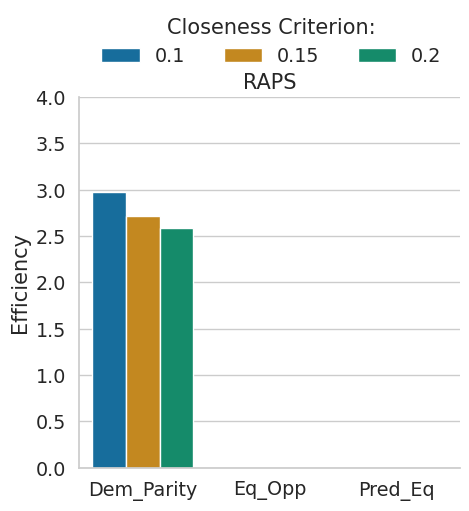

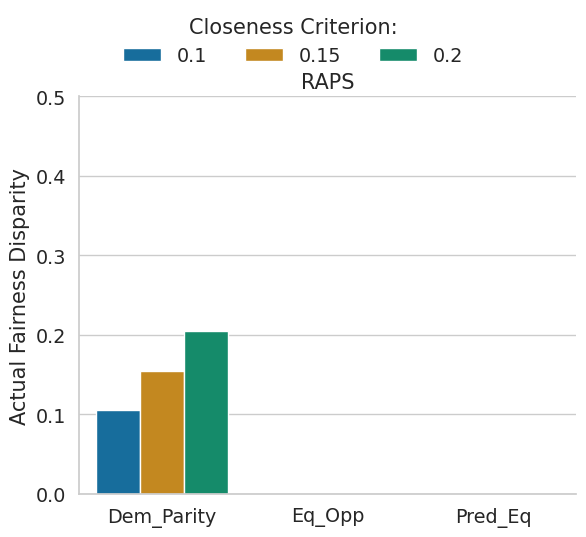

ACSIncome continental_all False Enhanced_Privacy


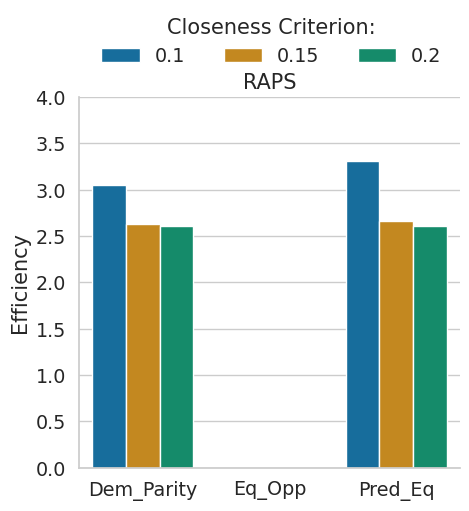

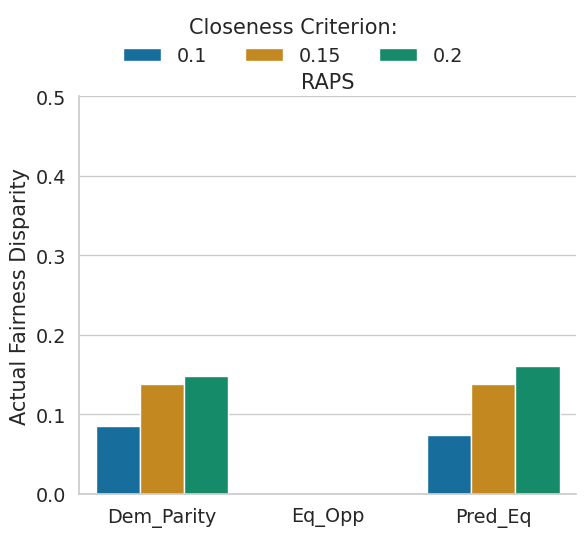

ACSIncome continental_all False Hybrid


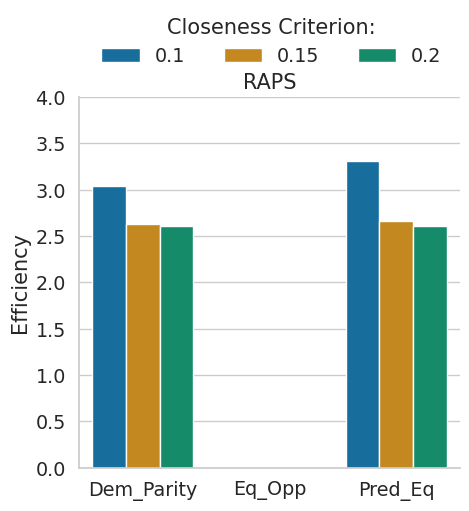

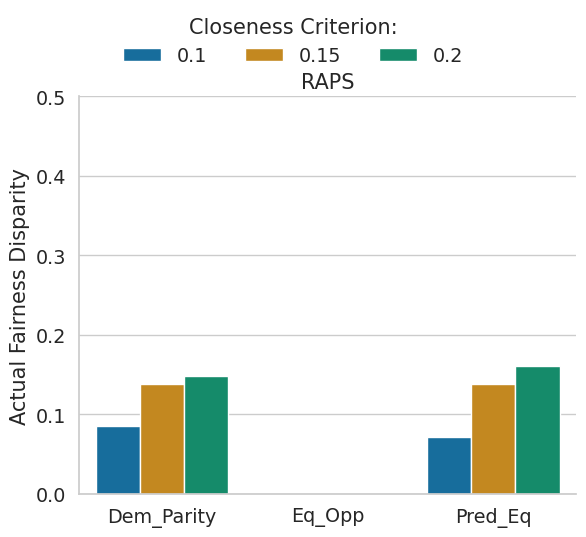

ACSIncome continental_all False Communication_Efficient


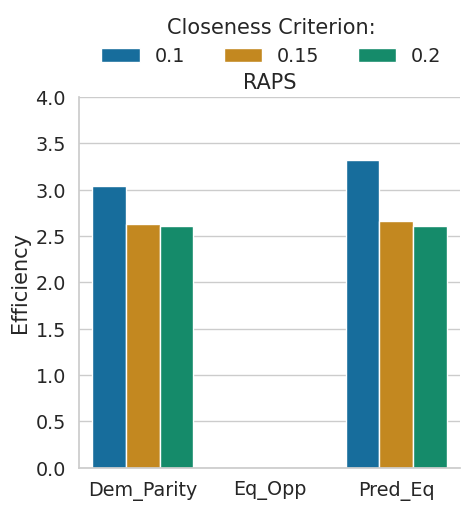

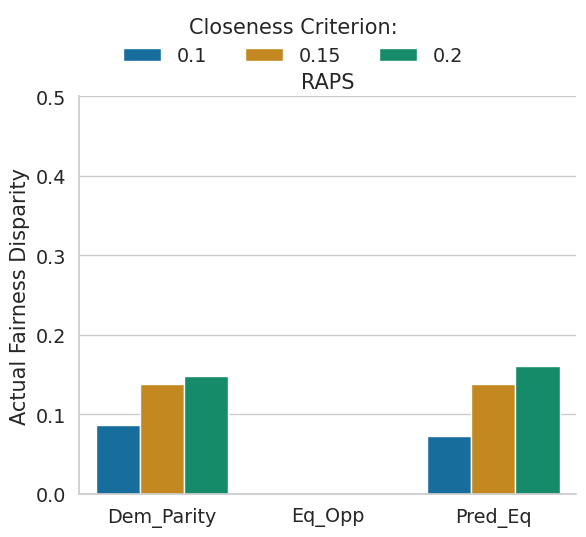

ACSIncome small False Communication_Efficient


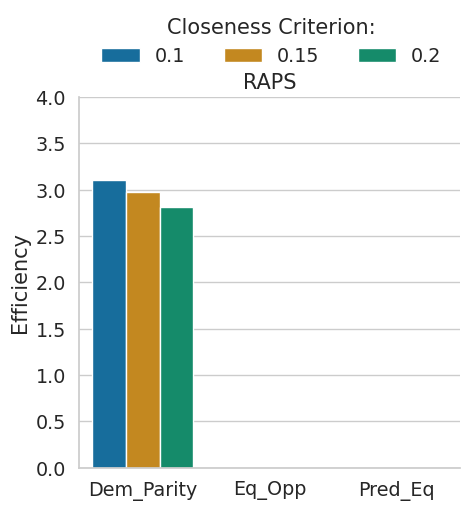

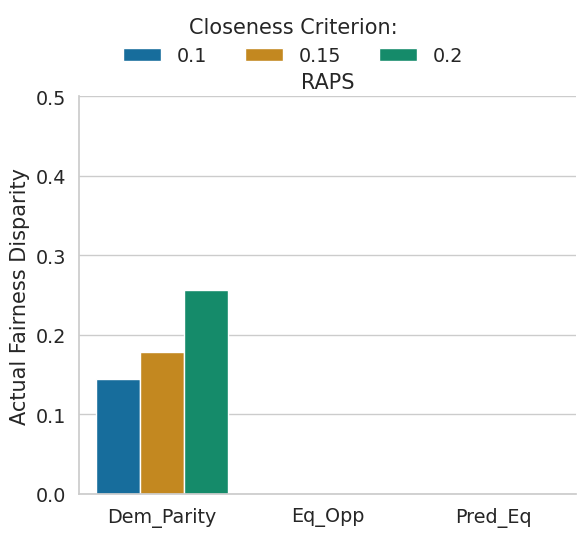

ACSEducation continental_all False Communication_Efficient


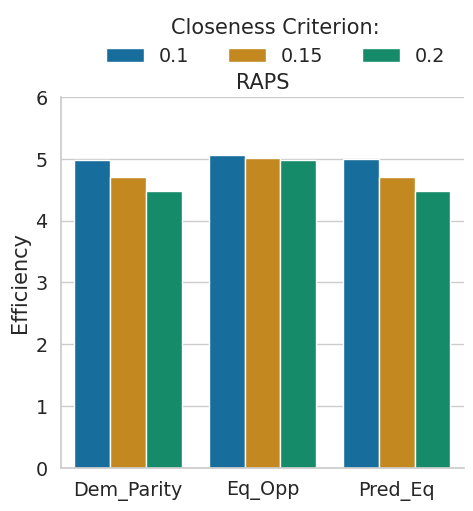

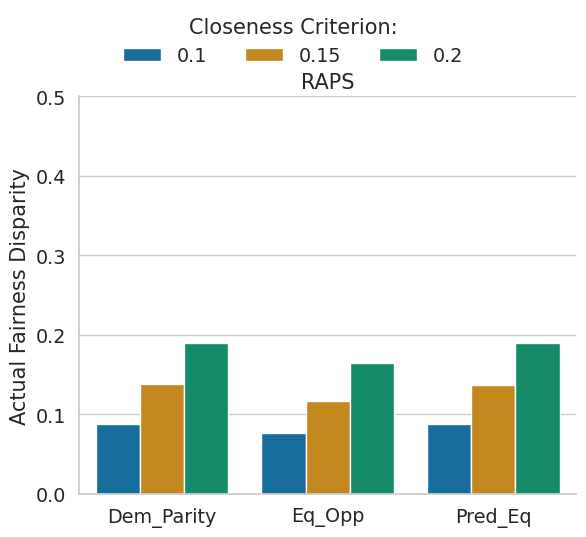

ACSEducation continental_all True Communication_Efficient


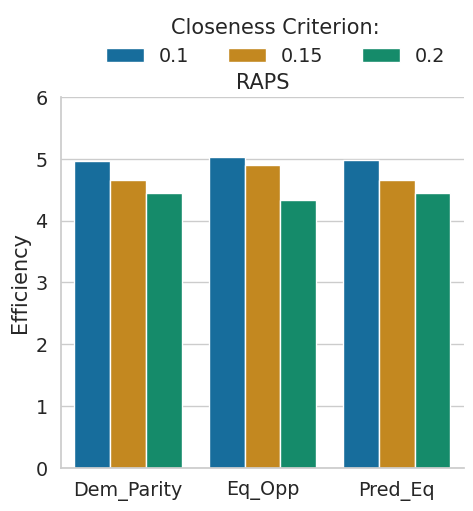

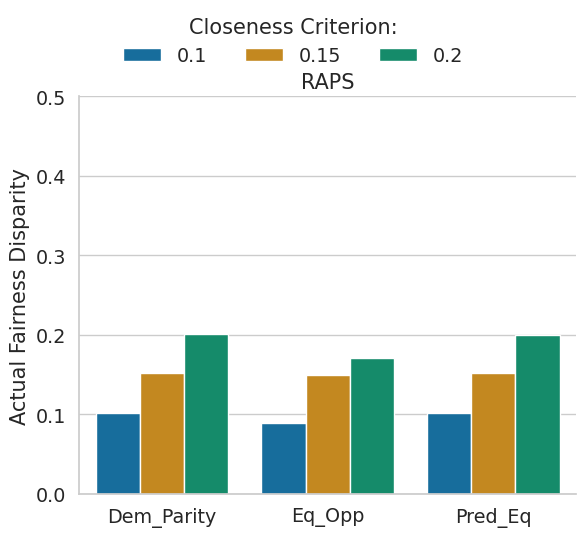

ACSEducation continental_small False Enhanced_Privacy


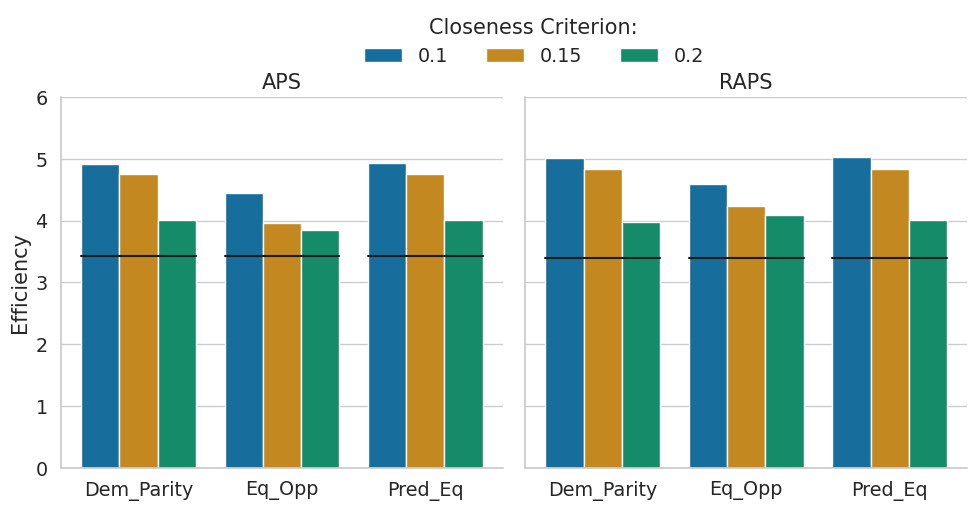

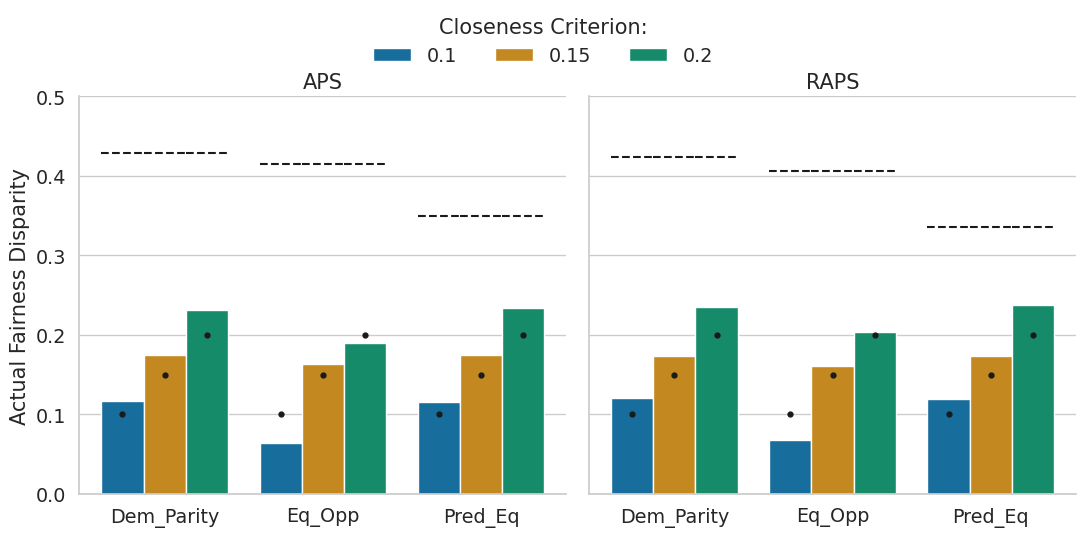

ACSEducation continental_small False Communication_Efficient


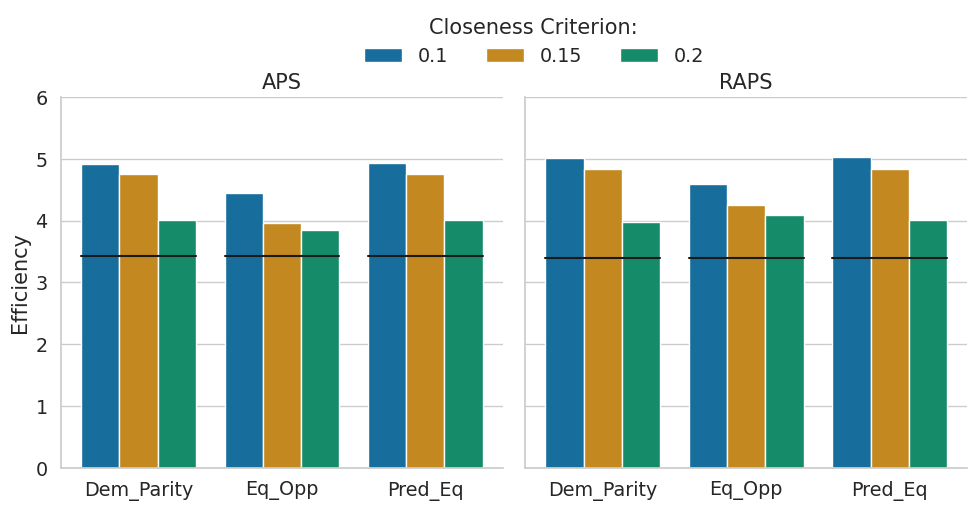

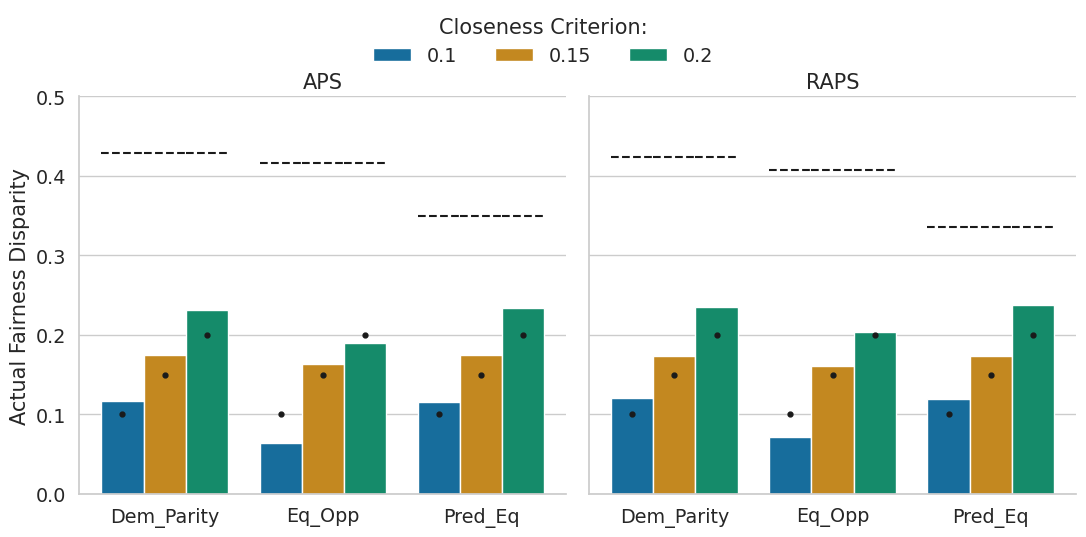

ACSEducation continental_small True Enhanced_Privacy


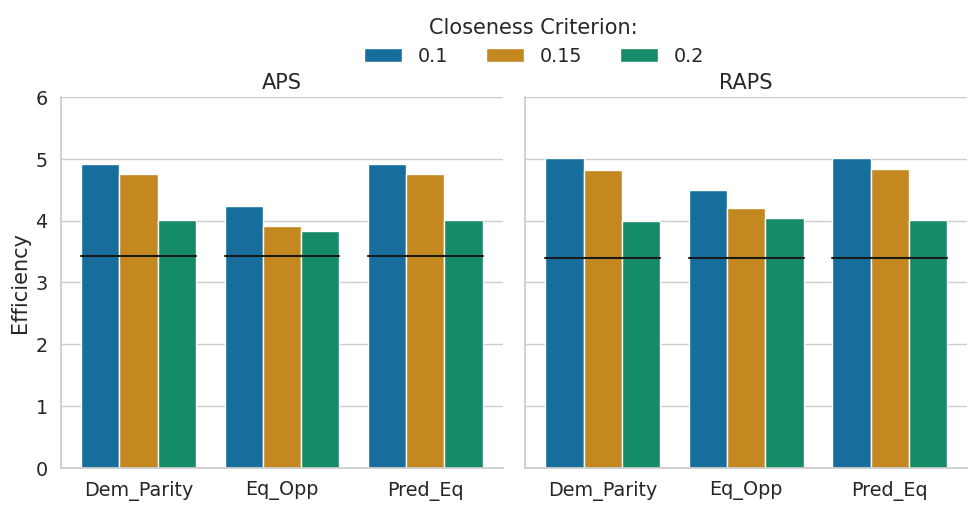

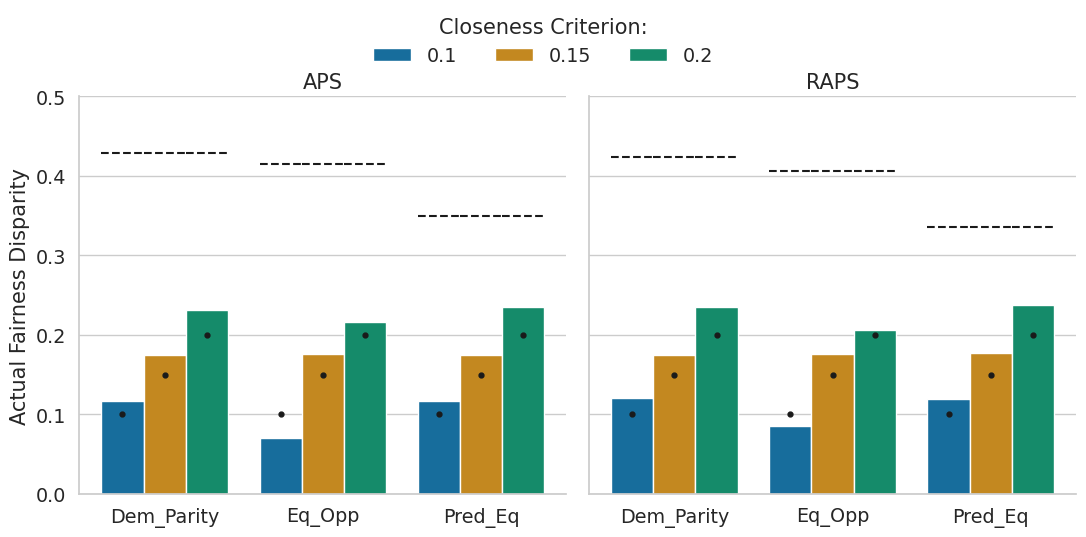

ACSEducation continental_small True Communication_Efficient


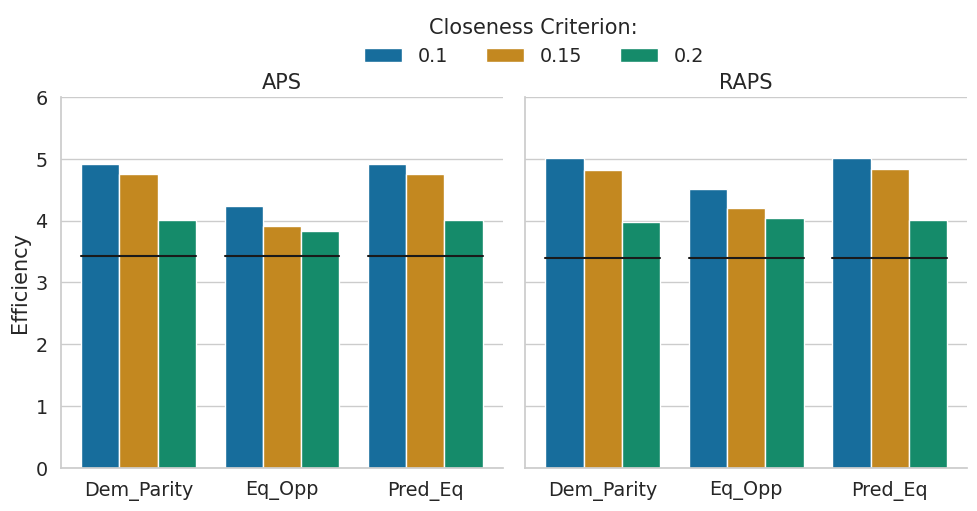

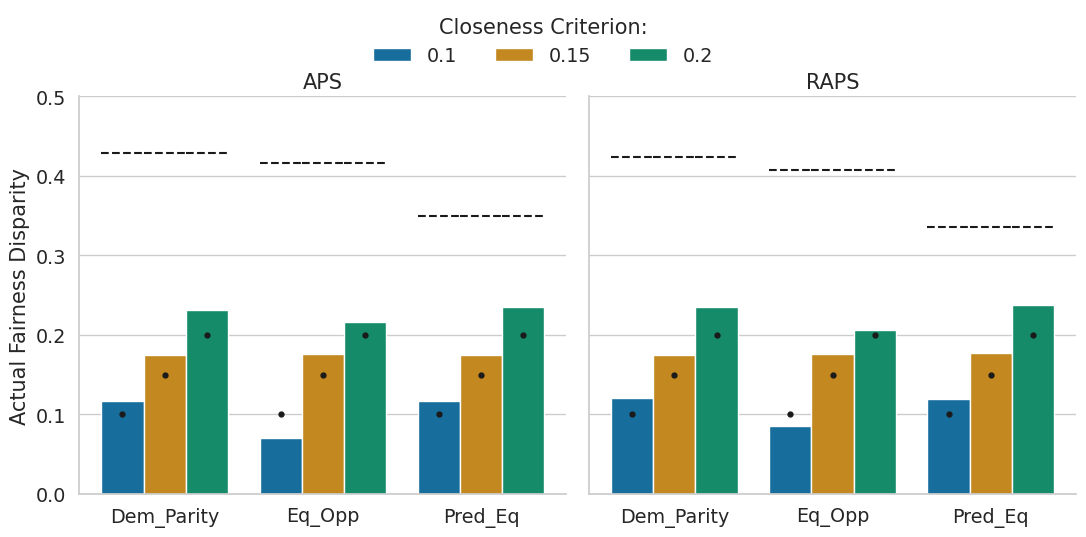

ACSEducation small False Enhanced_Privacy


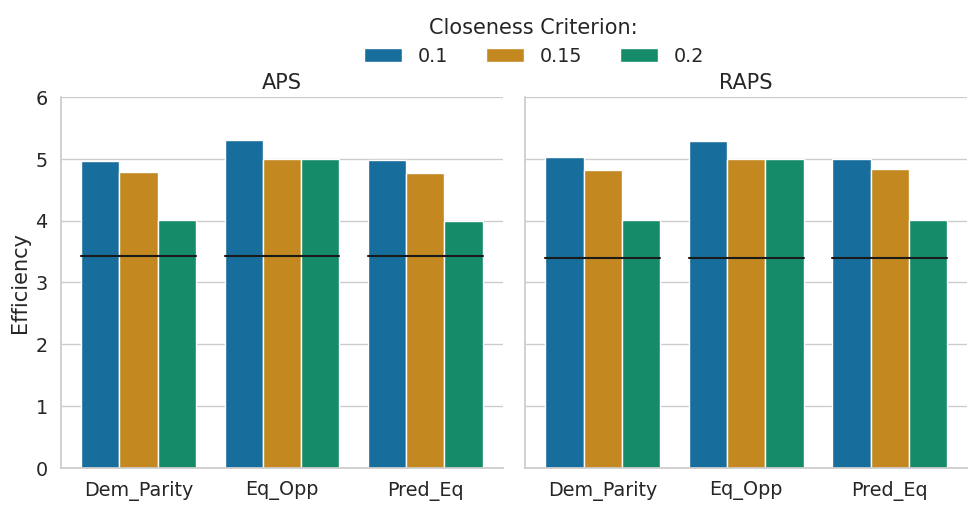

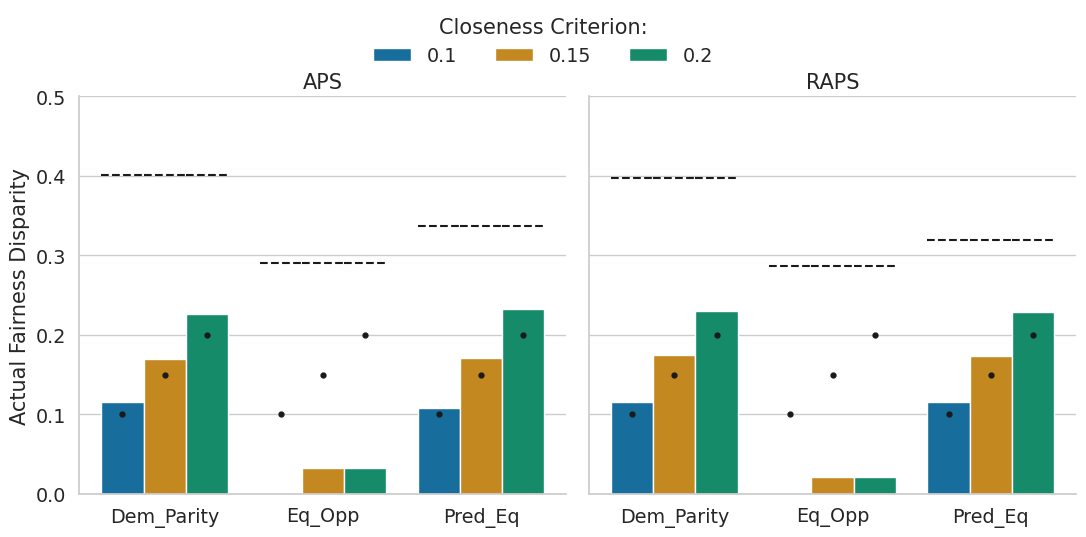

ACSEducation small False Communication_Efficient


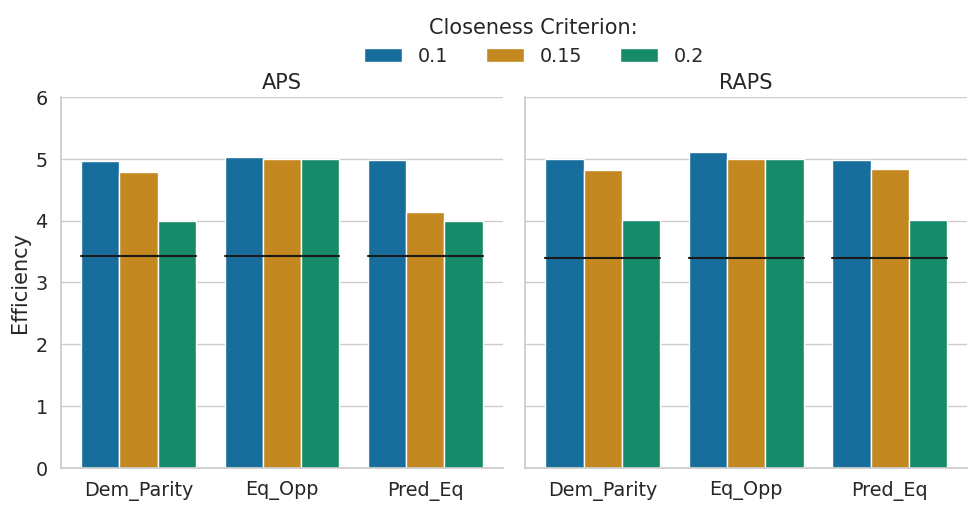

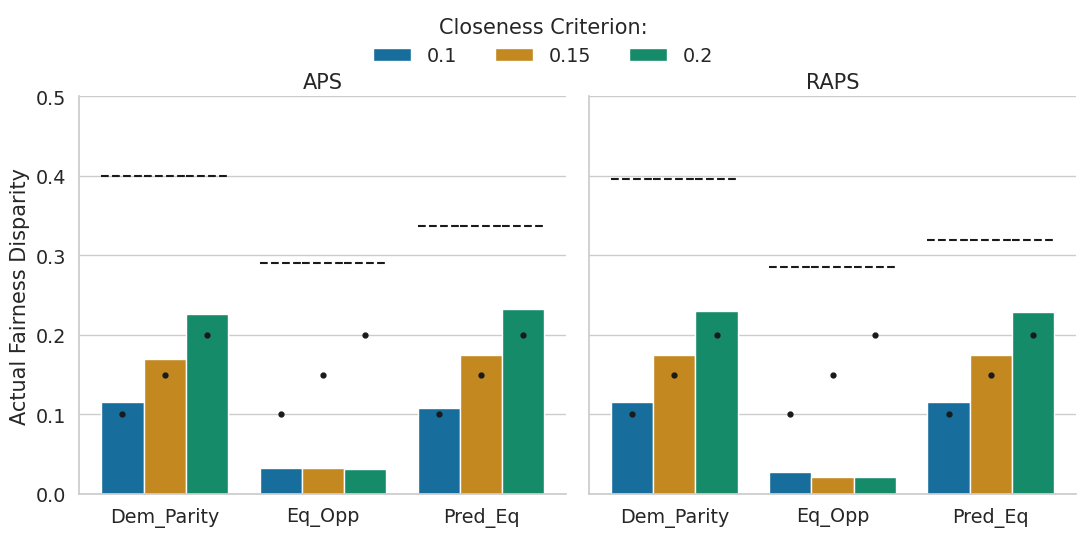

ACSEducation small True Enhanced_Privacy


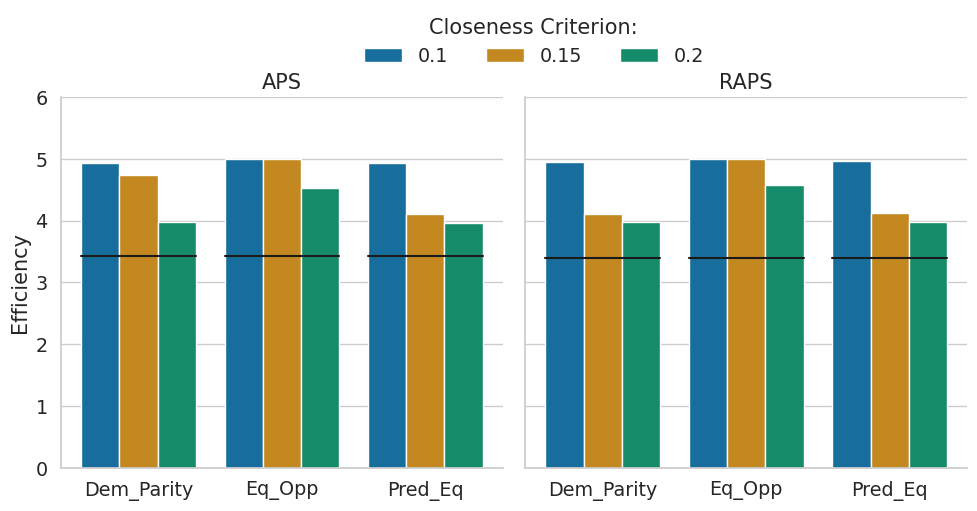

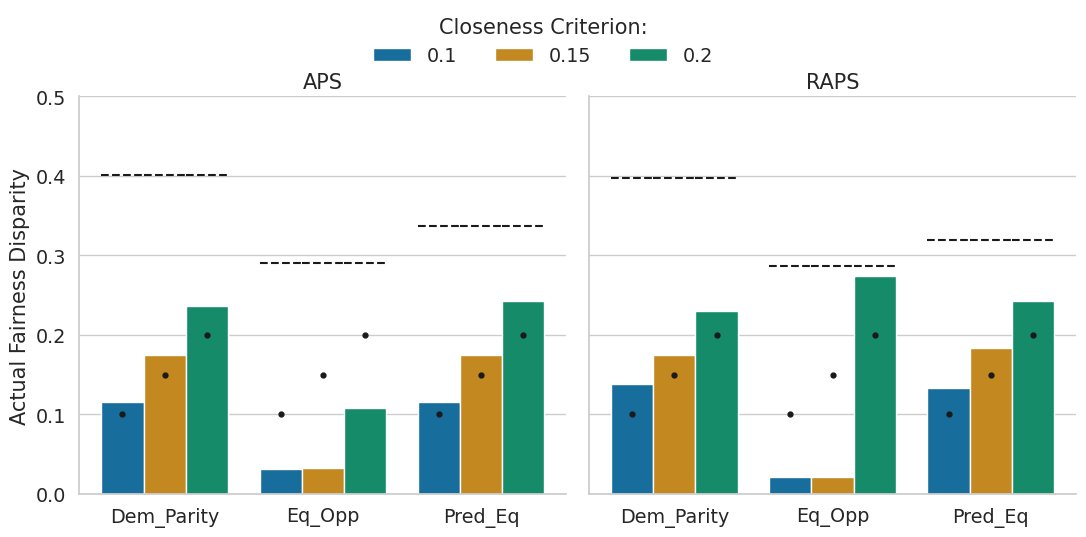

ACSEducation small True Communication_Efficient


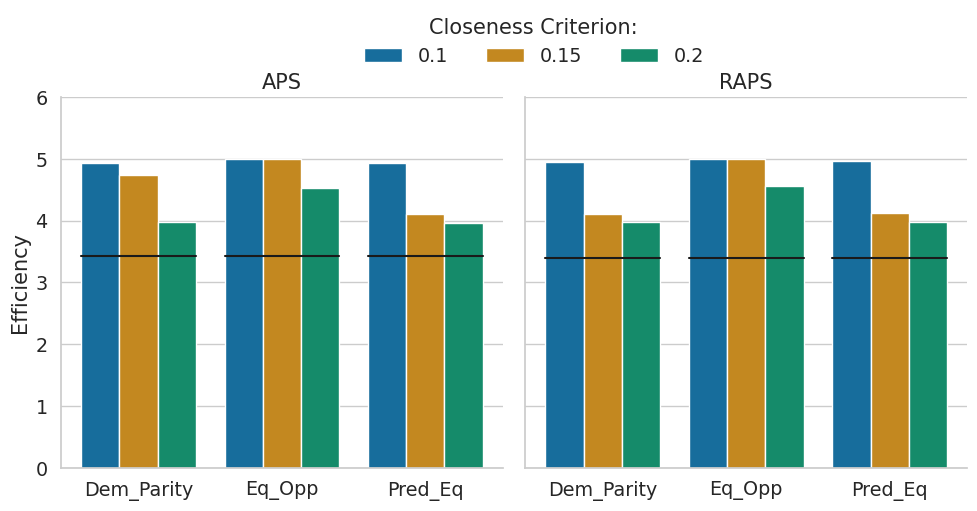

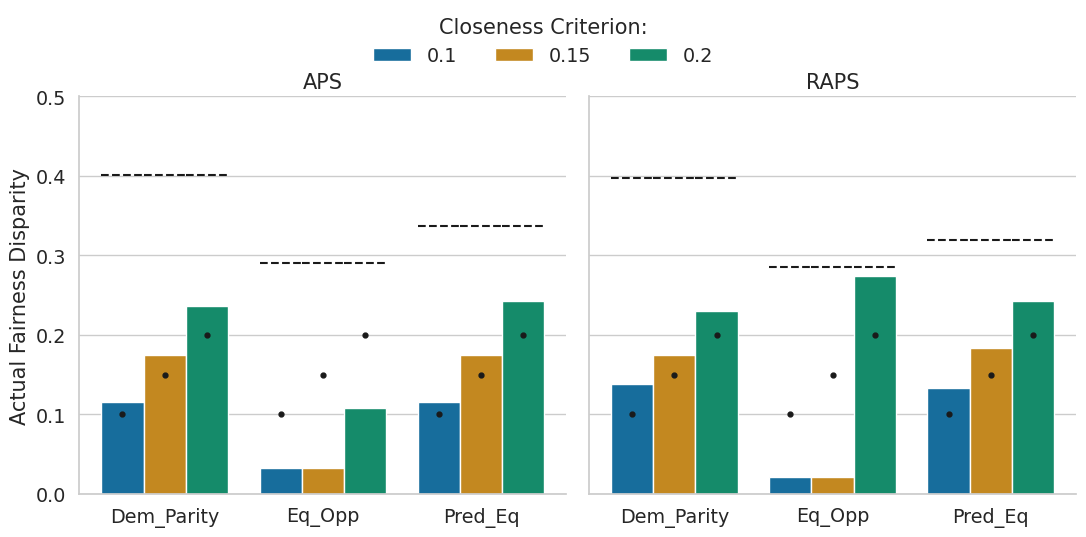

Fitzpatrick 1_clients False Communication_Efficient


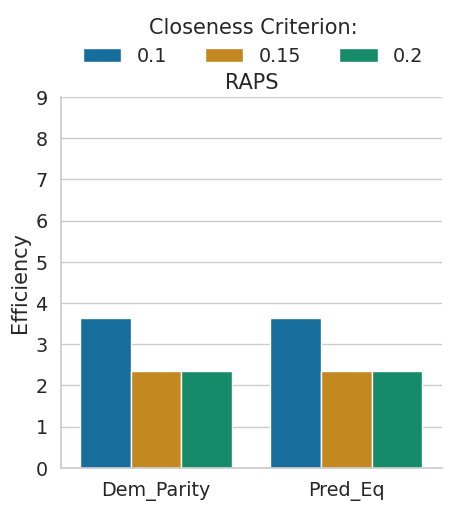

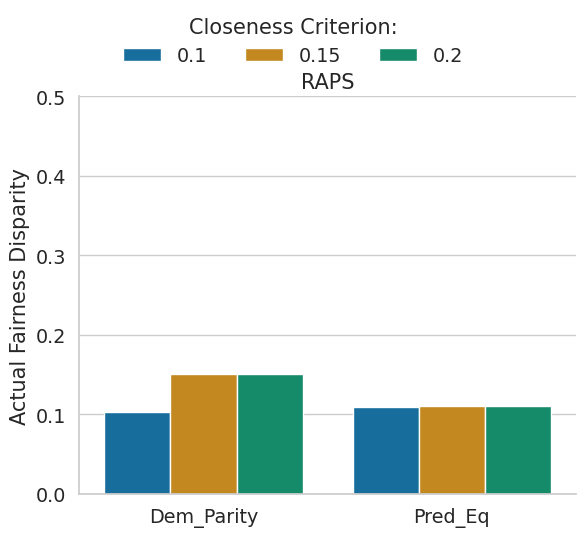

Fitzpatrick 2_clients False Communication_Efficient


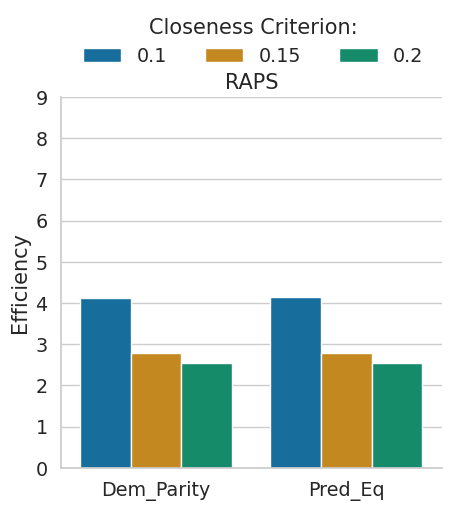

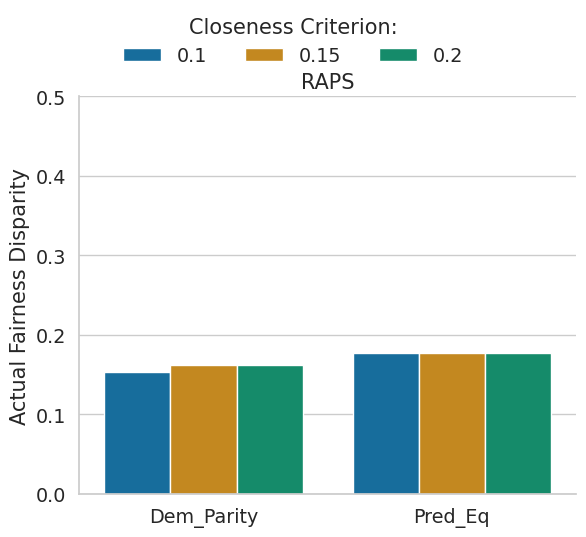

Fitzpatrick 4_clients False Communication_Efficient


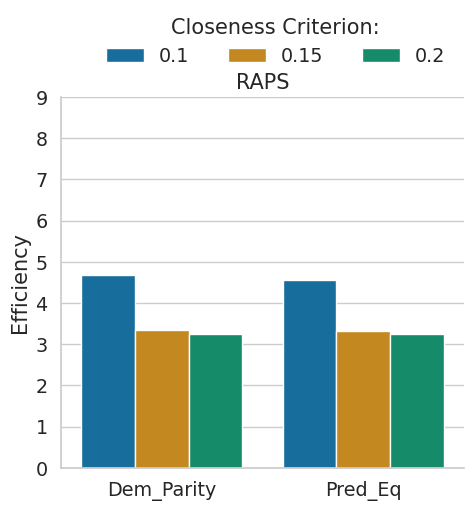

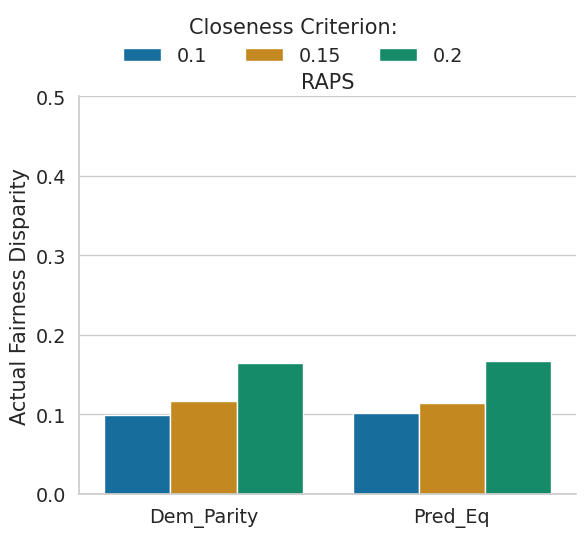

Fitzpatrick 8_clients False Enhanced_Privacy


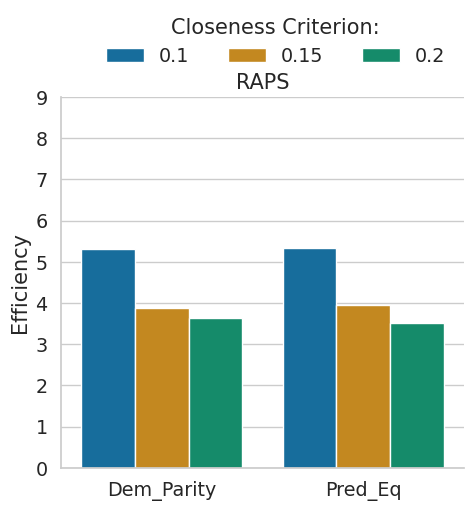

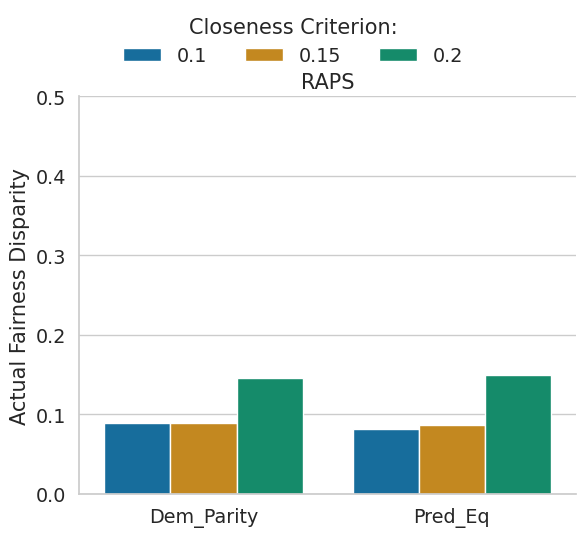

Fitzpatrick 8_clients False Hybrid


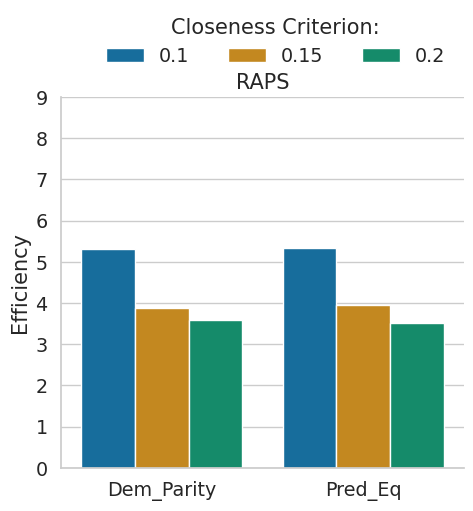

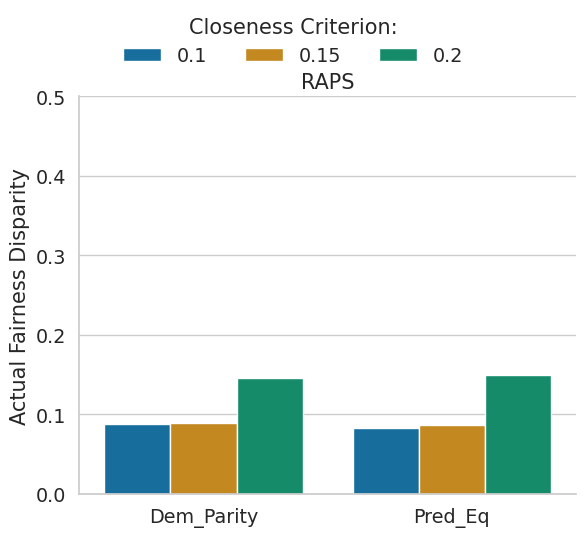

Fitzpatrick 8_clients False Communication_Efficient


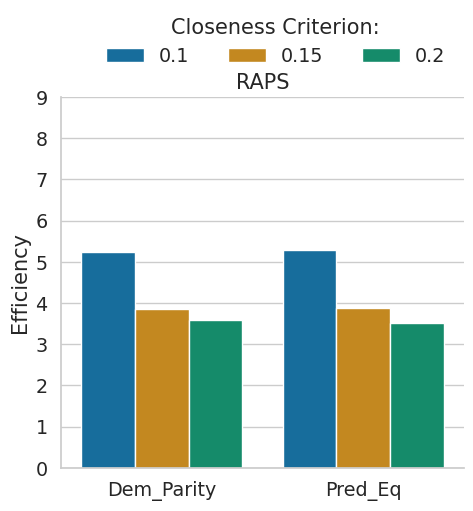

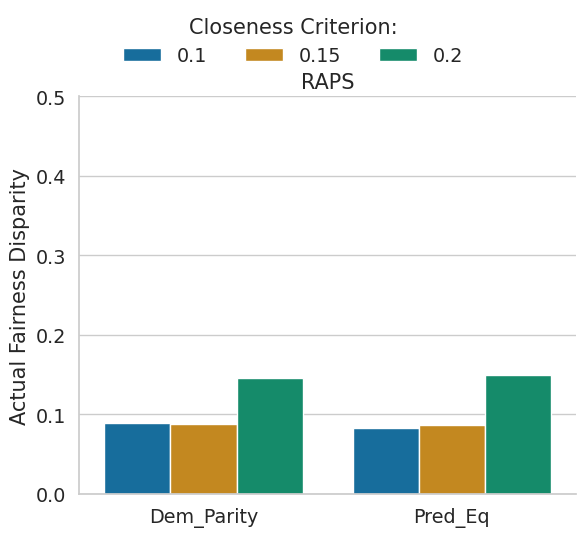

Pokec_gender 2_clients False Enhanced_Privacy


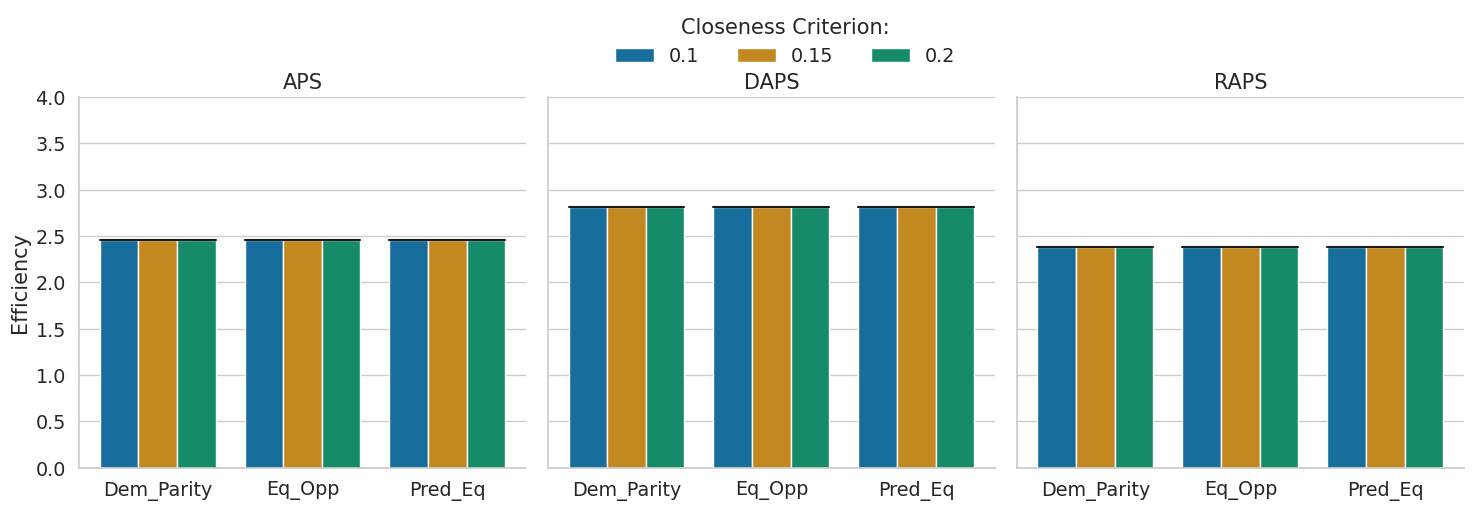

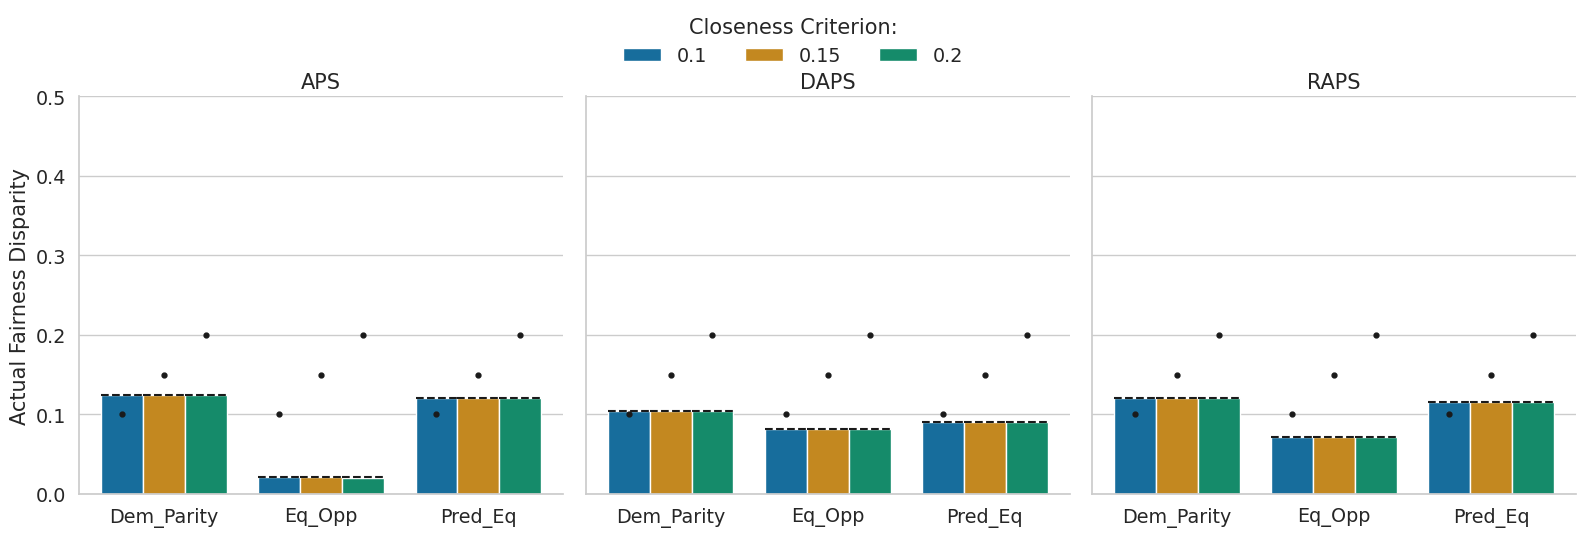

Pokec_gender 2_clients False Communication_Efficient


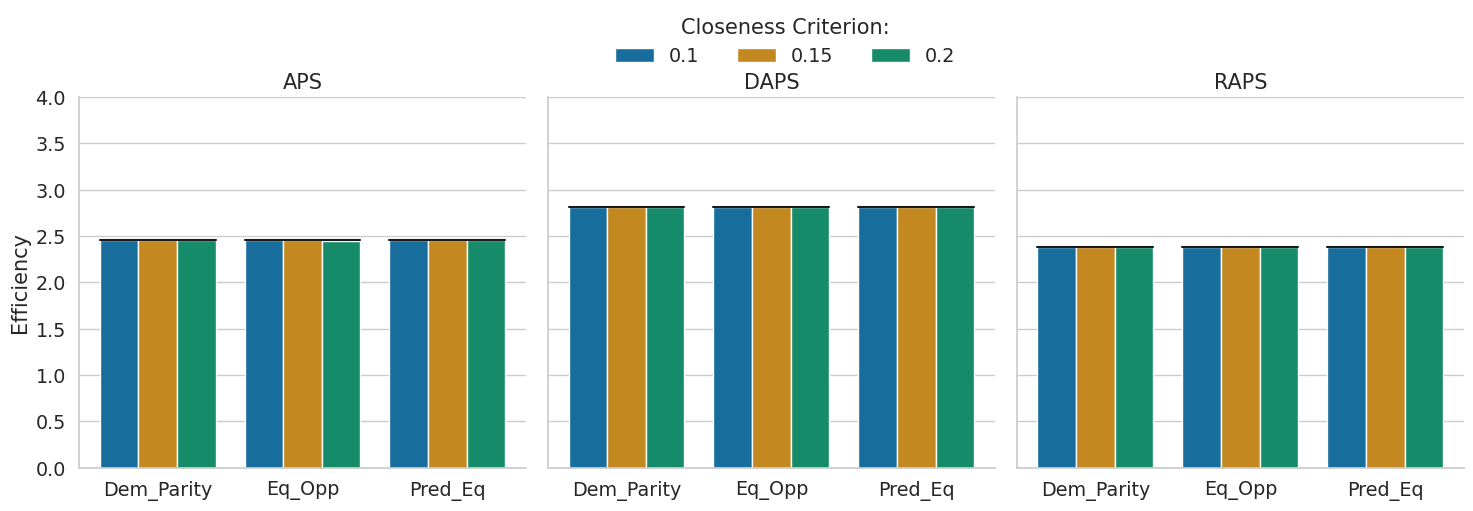

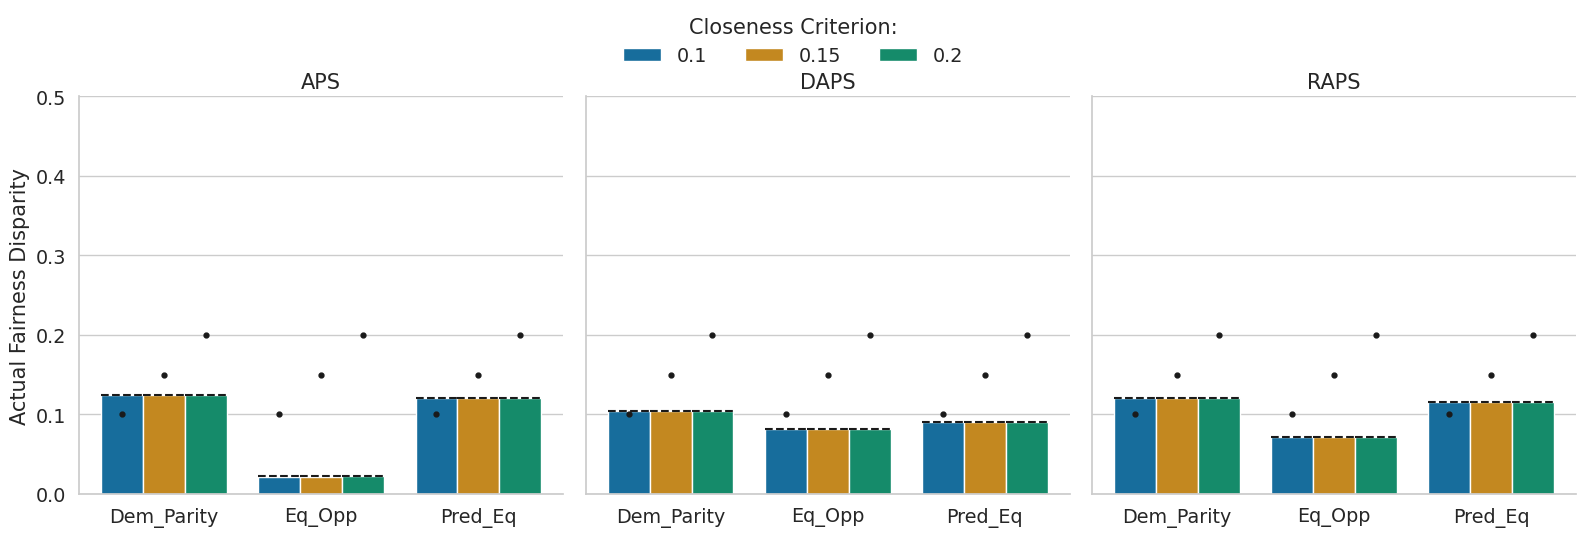

Pokec_region 2_clients False Enhanced_Privacy


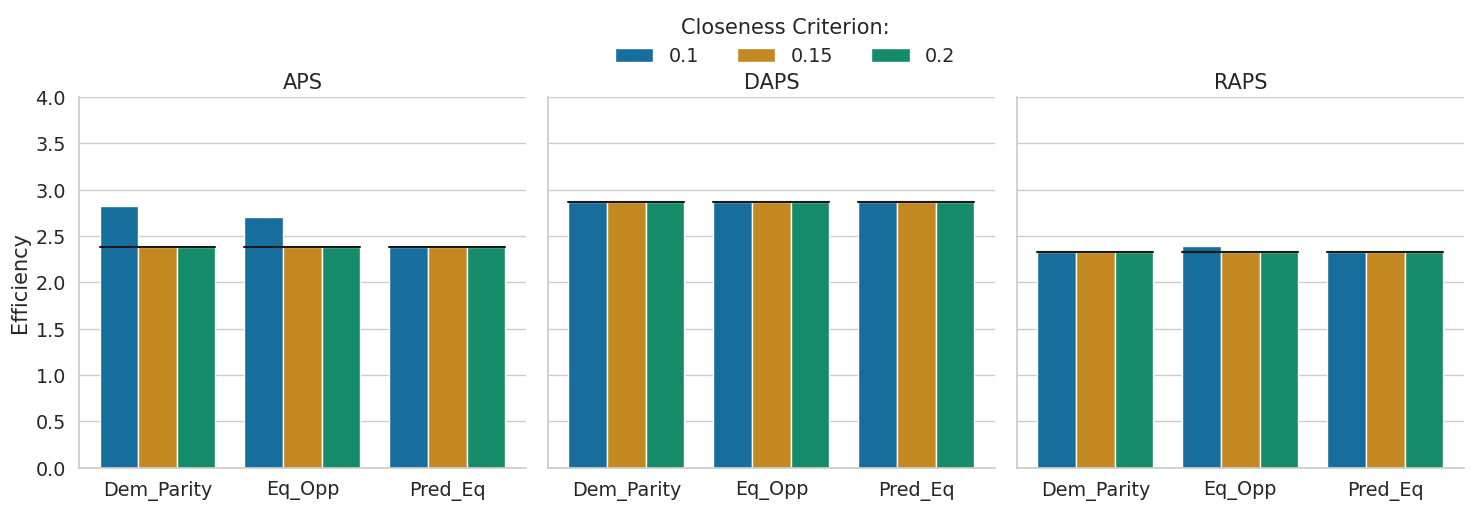

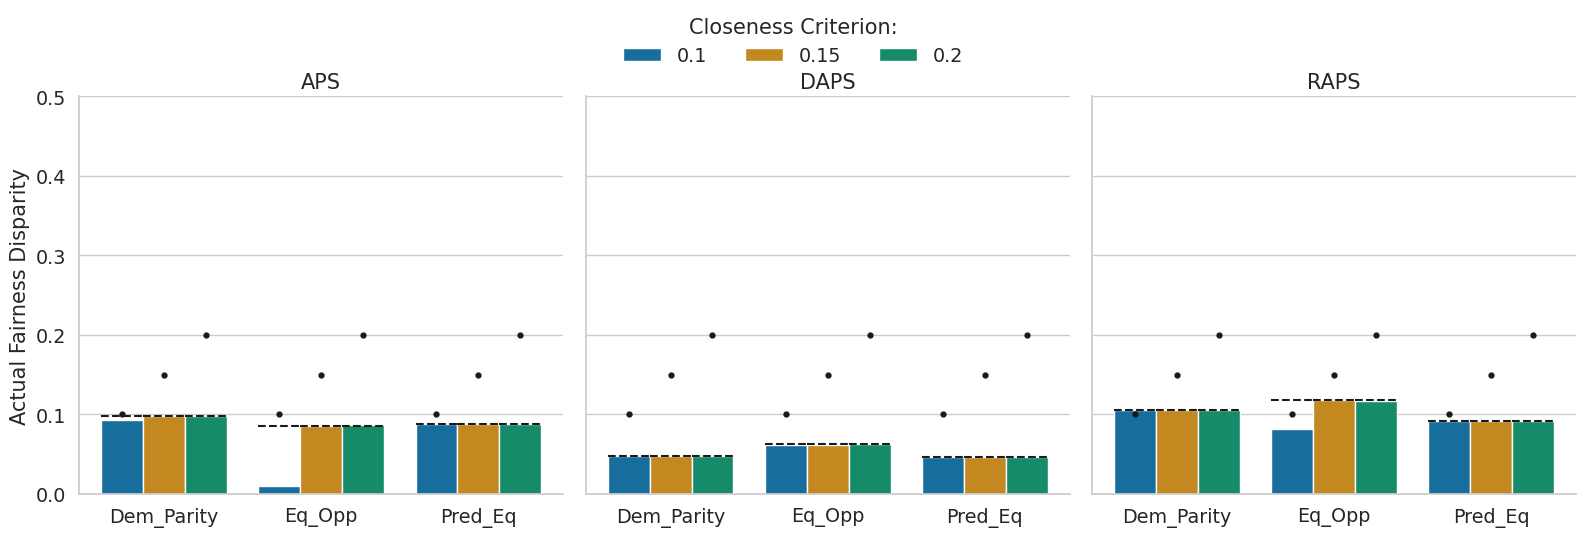

Pokec_region 2_clients False Communication_Efficient


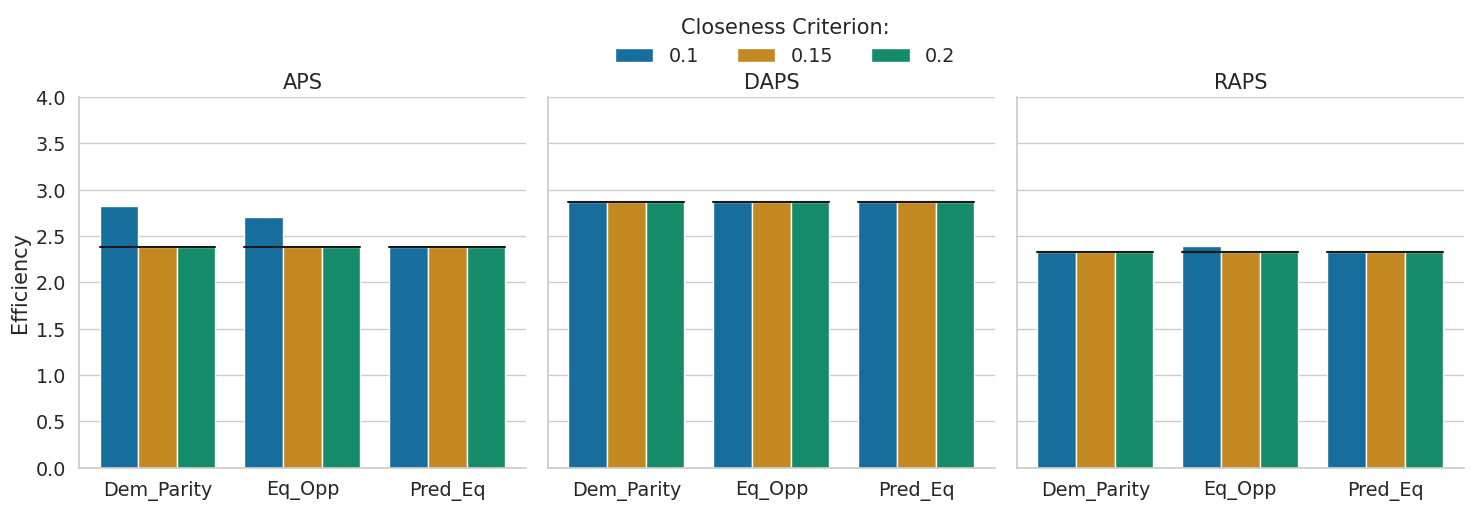

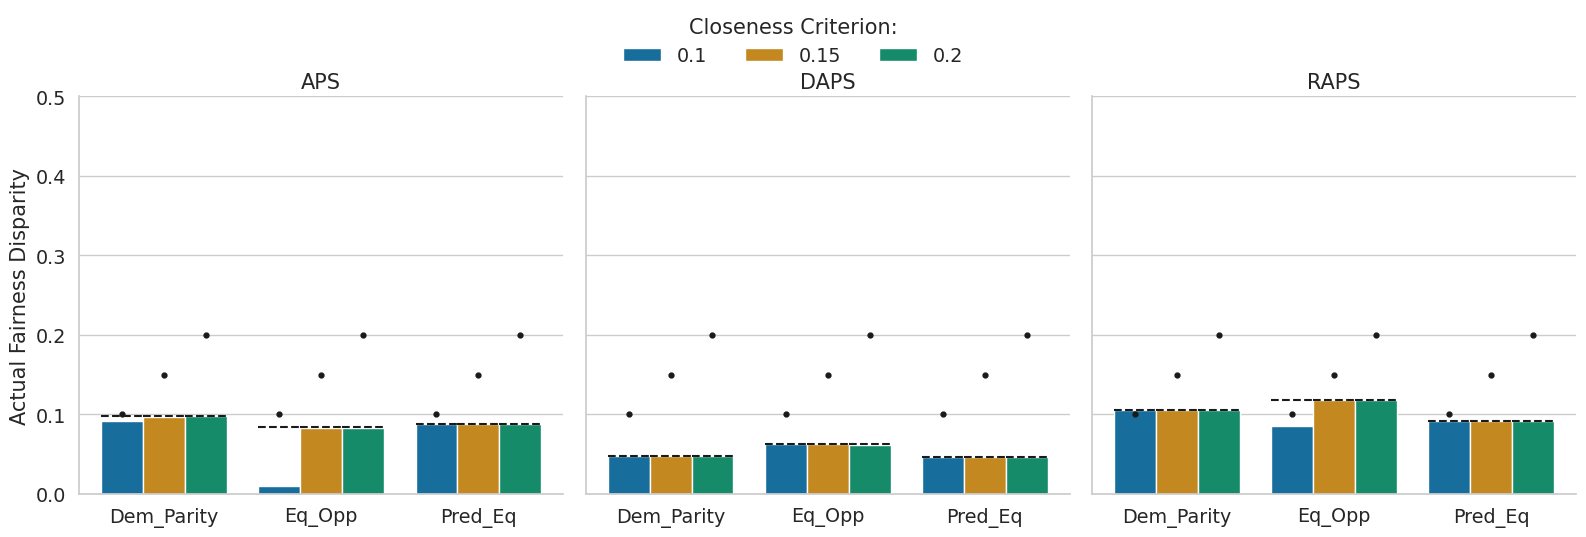

Pokec_region_gender 2_clients False Enhanced_Privacy


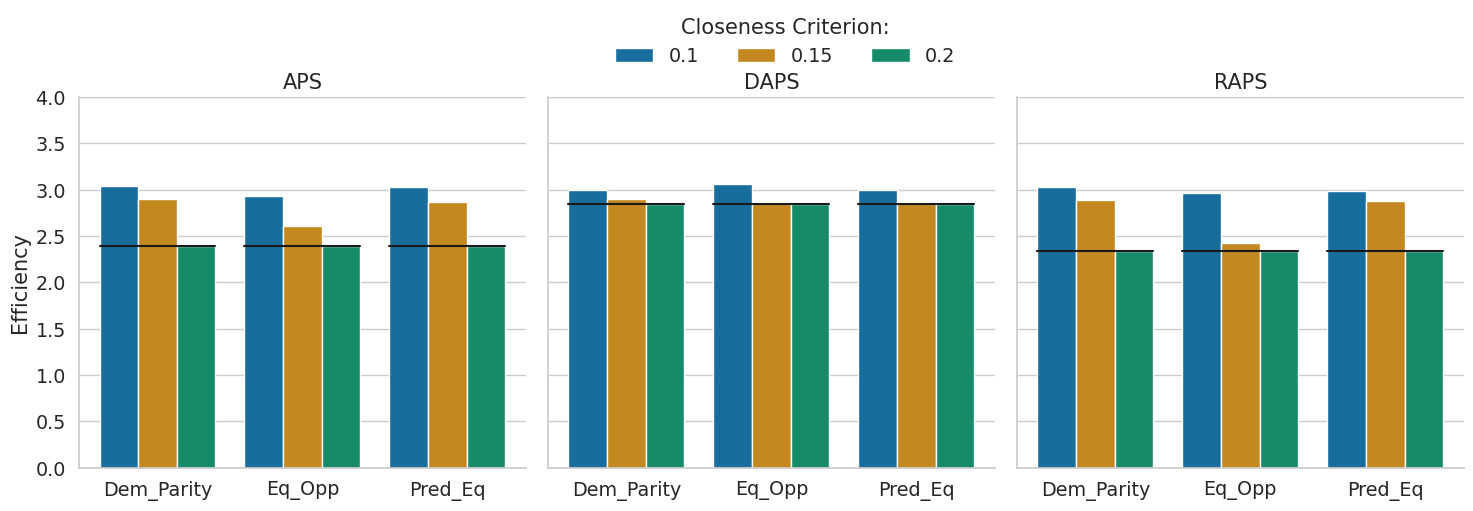

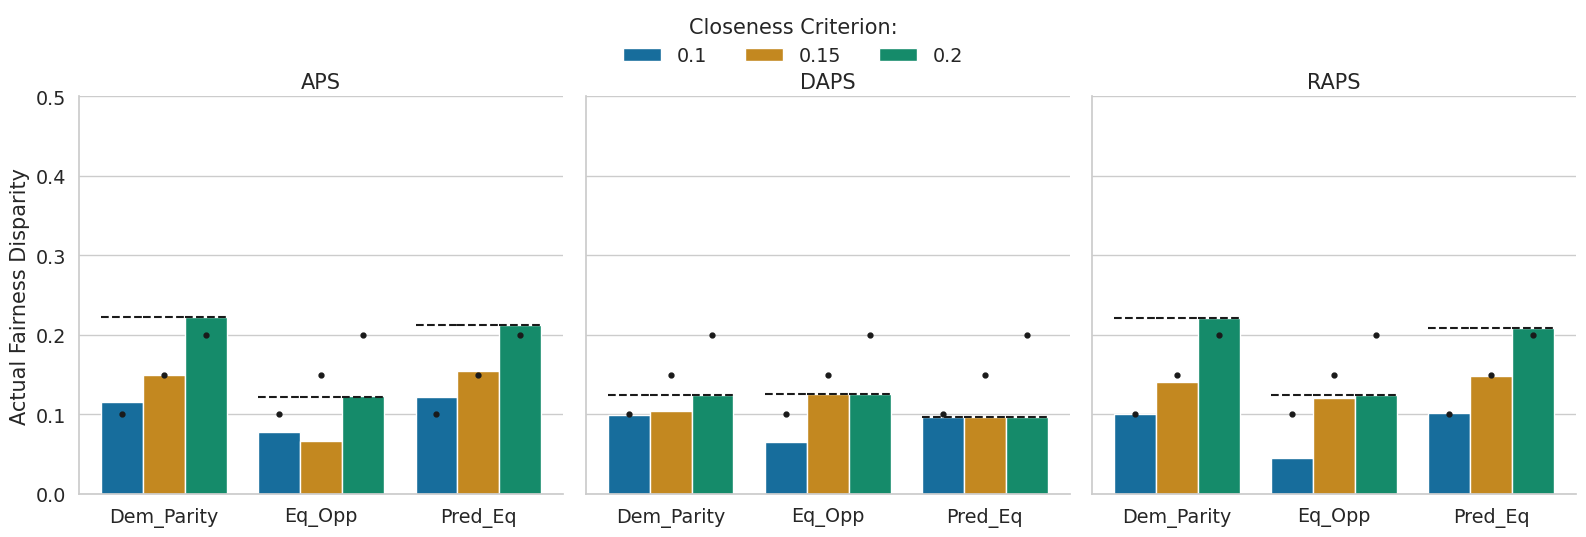

Pokec_region_gender 2_clients False Communication_Efficient


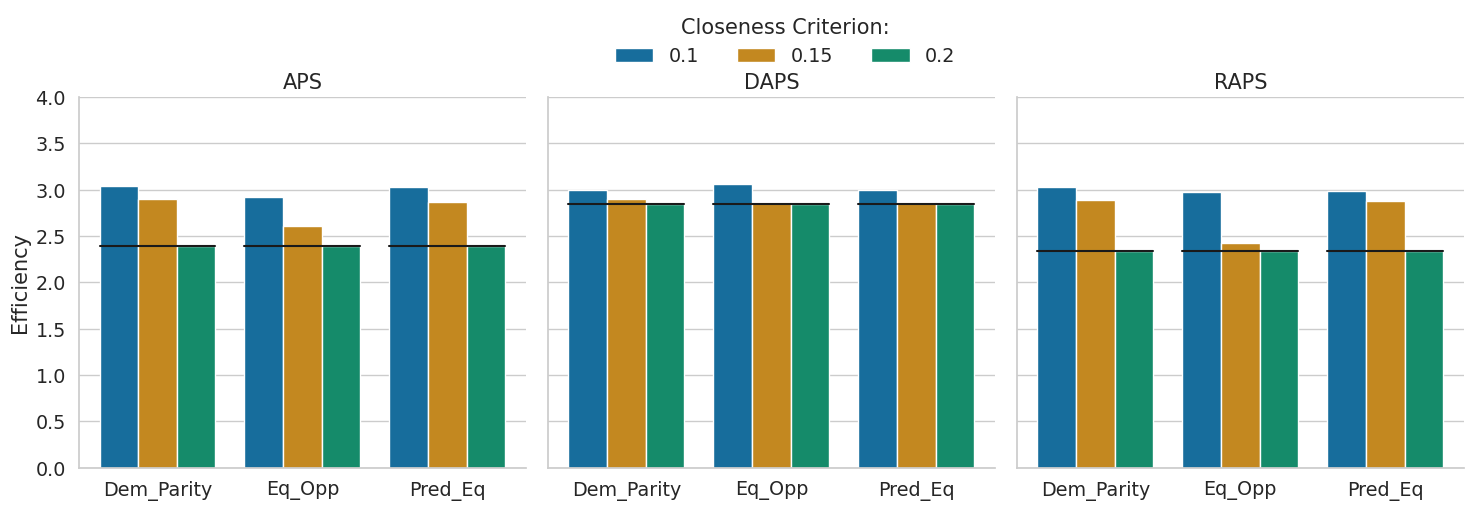

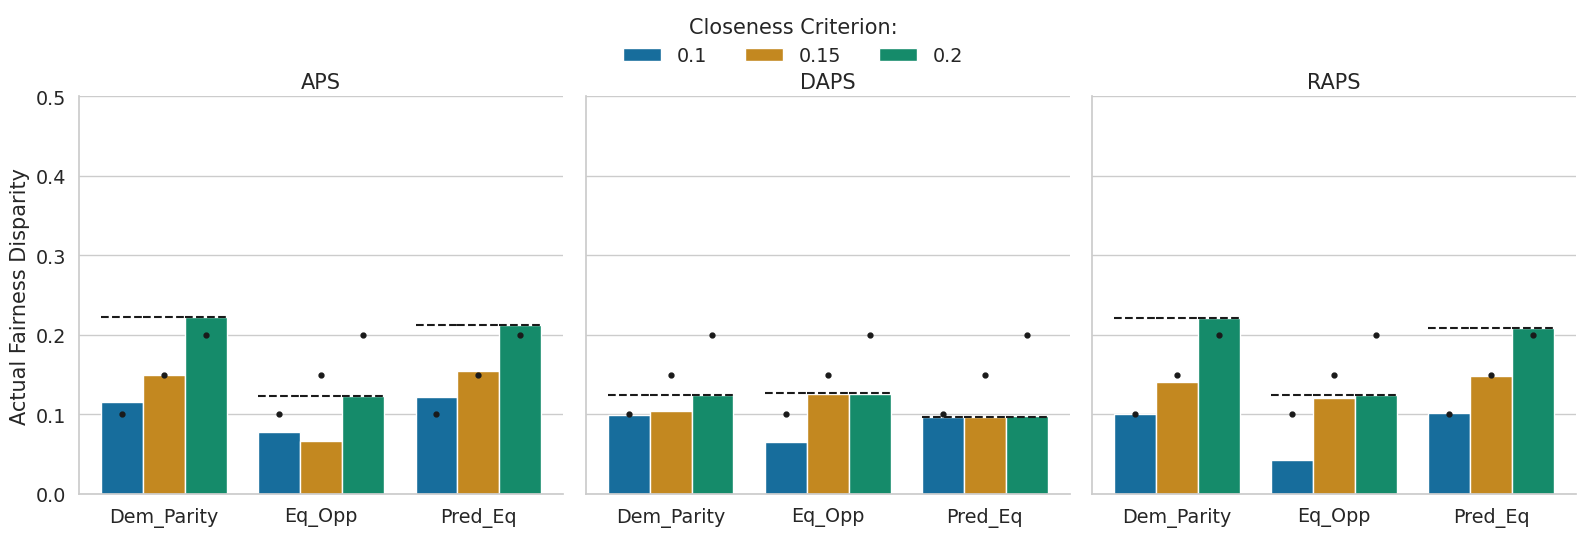

In [7]:
import matplotlib.pyplot as plt
import seaborn as sns

METRICS = list(map(lambda x: METRIC_MAP[x], ["Demographic_Parity", "Equal_Opportunity", "Predictive_Equality"]))

FITZPATRICK_METRICS = list(map(lambda x: METRIC_MAP[x], ["Demographic_Parity", "Predictive_Equality"]))

C = [0.1, 0.15, 0.2]
C_STR = [str(c) for c in C]  # fixes bar order and drops the extra elbow-sweep c values
for dataset_sens_attrs in res_df["dataset_sens_attrs"].unique():
    for client_type in res_df[res_df["dataset_sens_attrs"] == dataset_sens_attrs]["client_type"].unique():
        for use_mle in [False, True]:
            df = res_df[(res_df["dataset_sens_attrs"] == dataset_sens_attrs) & (res_df["use_mle"] == use_mle) & (res_df["client_type"] == client_type)]
            
            eff_lim = 4
            if "ACSEducation" in dataset_sens_attrs:
                metrics_list = METRICS
                eff_lim = 6
            elif "Fitzpatrick" in dataset_sens_attrs:
                metrics_list = FITZPATRICK_METRICS
                eff_lim = 9
            else:
                metrics_list = METRICS
                eff_lim = 4
            
            if "Pokec" in dataset_sens_attrs and not use_mle:
                CP_METHODS = ["aps", "daps", "raps_rand_no_mod"]
            else:
                CP_METHODS = ["aps", "raps_rand_no_mod"]

            filtered_df = df[(df["fairness_metric"].isin(metrics_list)) & (df["cp_method"].isin(CP_METHODS))]
            for formulation in filtered_df["formulation"].dropna().unique():
                fdf = filtered_df[filtered_df["formulation"] == formulation].copy()
                if fdf.empty:
                    continue
                
                ours_df = fdf[fdf["type"] == "ours"]
                print(dataset_sens_attrs, client_type, use_mle, formulation)

                # Plot efficiency
                grid = sns.catplot(
                    data=ours_df,
                    x="fairness_metric",
                    y="eff_mean",
                    hue="c",
                    hue_order=C_STR,
                    col="cp_method",
                    kind="bar",
                    errorbar=None,
                    order=metrics_list,
                    sharex=False,
                )

                grid.set(xlabel="")
                grid.set(ylabel="Efficiency")
                grid.set(ylim=(0, eff_lim))
                axes_eff = [None] * len(CP_METHODS)
                for key, ax in grid.axes_dict.items():
                  ax.set_title(key.split("_")[0].upper())
                  axes_eff[CP_METHODS.index(key)] = ax
                sns.move_legend(grid, "upper center", bbox_to_anchor=(0.5, 1.1), ncol=len(C))
                grid.legend.set_title("Closeness Criterion:")

                # Plot violation
                grid2 = sns.catplot(
                    data=ours_df,
                    x="fairness_metric",
                    y="violation_mean",
                    hue="c",
                    hue_order=C_STR,
                    col="cp_method",
                    kind="bar",
                    order=metrics_list,
                    errorbar=None,
                    sharex=False,
                )
                grid2.set(xlabel="")
                grid2.set(ylabel="Actual Fairness Disparity")

                grid2.set(ylim=(0, 0.5), yticks=[0, 0.1, 0.2, 0.3, 0.4, 0.5])
                axes_viol = [None] * len(CP_METHODS)
                for key, ax in grid2.axes_dict.items():
                  ax.set_title(key.split("_")[0].upper())
                  axes_viol[CP_METHODS.index(key)] = ax
                sns.move_legend(grid2, "upper center", bbox_to_anchor=(0.5, 1.1), ncol=len(C))
                grid2.legend.set_title("Closeness Criterion:")

                # Add the base FCP method lines and points
                axes_idx = 0
                for i in range(len(CP_METHODS)):
                    base_cp_df = fdf[(fdf["type"] == "base") & (fdf["cp_method"] == CP_METHODS[i])]
                    if base_cp_df.empty:
                        continue
                    
                    # Efficiency base line
                    ax_eff = axes_eff[axes_idx]
                    if ax_eff is None:
                        continue

                    patches = ax_eff.patches

                    for ix, a in enumerate(patches):
                        x_start = a.get_x()
                        width = a.get_width()
                        if width == 0: 
                            continue

                        eff_mean = base_cp_df[(base_cp_df["fairness_metric"] == metrics_list[ix % len(metrics_list)]) & (base_cp_df["client_type"] == client_type)]["eff_mean"].mean()
                        ax_eff.plot([x_start, x_start + width], [eff_mean] * 2, '-', c='k')

                    # Violation base line and marker
                    ax_viol = axes_viol[axes_idx]
                    patches = ax_viol.patches

                    for ix, a in enumerate(patches):
                        x_start = a.get_x()
                        width = a.get_width()
                        if width == 0: 
                            continue

                        violation_mean = base_cp_df[(base_cp_df["fairness_metric"] == metrics_list[ix % len(metrics_list)]) & (base_cp_df["client_type"] == client_type)]["violation_mean"].mean()
                        ax_viol.plot([x_start, x_start + width], [violation_mean] * 2, '--', c='k')
                        ax_viol.plot(x_start + width / 2, float(C[ix // len(metrics_list)]), 'o', c='k', markersize=3.5)
                    
                    axes_idx += 1
                    
                plt.tight_layout()
                form_slug = str(formulation).replace(" ", "_")
                # Save the figure
                grid.savefig(f"./figures/{str(dataset_sens_attrs).strip('_')}_{client_type}_{use_mle}_{form_slug}_efficiency.pdf", bbox_inches='tight')
                grid2.savefig(f"./figures/{str(dataset_sens_attrs).strip('_')}_{client_type}_{use_mle}_{form_slug}_violation.pdf", bbox_inches='tight')

                plt.show() 


,c,dataset_sens_attrs,client_type,use_mle,cp_method,fairness_metric,type,num_client_formulation_0,num_client_formulation_1,use_descent,use_group_info,num_opt_rounds,n_seeds,eff_mean,violation_mean,eff_std,violation_std,formulation,eff/viol
136,0.1,Fitzpatrick,1_clients,False,raps_rand_no_mod,Dem_Parity,base,1,0,True,False,100.0,3,2.3560,0.1510,0.0000,0.0000,Communication_Efficient,2.356 / 0.151
137,0.1,Fitzpatrick,1_clients,False,raps_rand_no_mod,Dem_Parity,ours,1,0,True,False,100.0,3,3.6470,0.1030,0.0000,0.0000,Communication_Efficient,3.647 / 0.103
138,0.1,Fitzpatrick,1_clients,False,raps_rand_no_mod,Pred_Eq,base,1,0,True,False,100.0,3,2.3560,0.1110,0.0000,0.0000,Communication_Efficient,2.356 / 0.111
139,0.1,Fitzpatrick,1_clients,False,raps_rand_no_mod,Pred_Eq,ours,1,0,True,False,100.0,3,3.6470,0.1090,0.0000,0.0000,Communication_Efficient,3.647 / 0.109
140,0.1,Fitzpatrick,2_clients,False,raps_rand_no_mod,Dem_Parity,base,2,0,True,False,100.0,3,2.5417,0.1617,0.0012,0.0012,Communication_Efficient,2.542 / 0.162
141,0.1,Fitzpatrick,2_clients,False,raps_rand_no_mod,Dem_Parity,ours,2,0,True,False,100.0,3,4.1220,0.1530,0.0156,0.0000,Communication_Efficient,4.122 / 0.153
142,0.1,Fitzpatrick,2_clients,False,raps_rand_no_mod,Pred_Eq,base,2,0,True,False,100.0,3,2.5423,0.1770,0.0012,0.0000,Communication_Efficient,2.542 / 0.177
143,0.1,Fitzpatrick,2_clients,False,raps_rand_no_mod,Pred_Eq,ours,2,0,True,False,100.0,3,4.1397,0.1770,0.0006,0.0000,Communication_Efficient,4.140 / 0.177
144,0.1,Fitzpatrick,4_clients,False,raps_rand_no_mod,Dem_Parity,base,4,0,True,False,100.0,3,2.8467,0.2937,0.0046,0.0012,Communication_Efficient,2.847 / 0.294
145,0.1,Fitzpatrick,4_clients,False,raps_rand_no_mod,Dem_Parity,ours,4,0,True,False,100.0,3,4.6840,0.0990,0.0000,0.0000,Communication_Efficient,4.684 / 0.099


Fitzpatrick comparison False Communication_Efficient


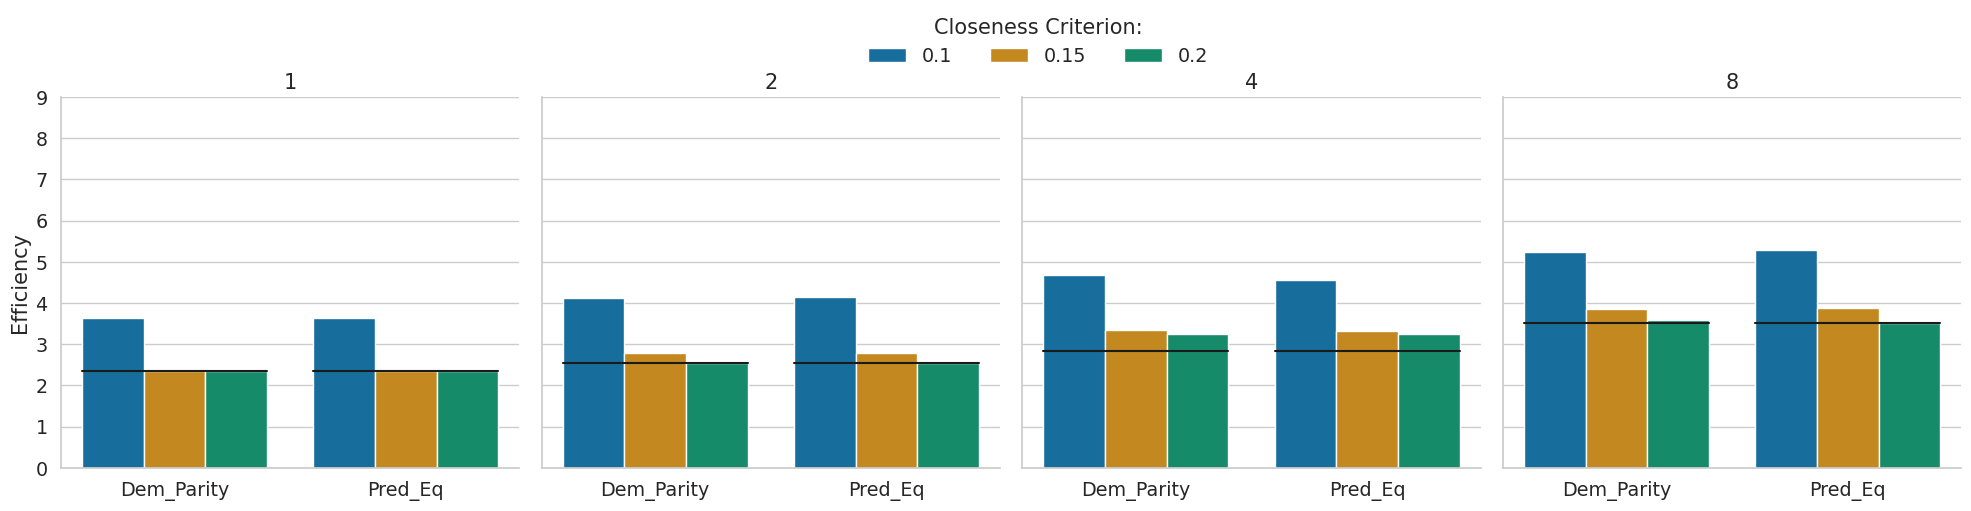

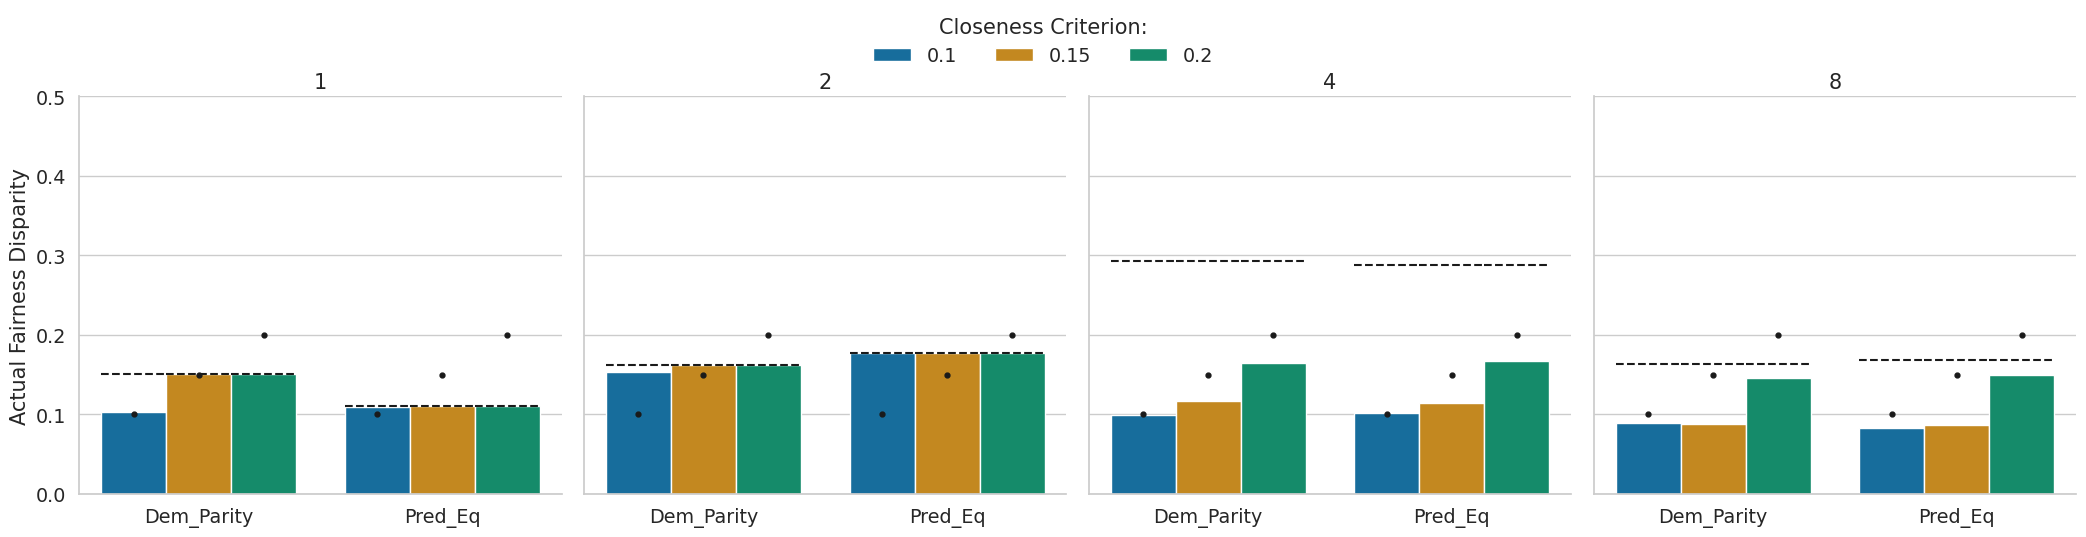

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

METRICS = list(map(lambda x: METRIC_MAP[x], ["Demographic_Parity", "Predictive_Equality"]))

C = [0.1, 0.15, 0.2]
CP_METHODS = ["raps_rand_no_mod"]
CLIENT_TYPES = ["1_clients", "2_clients", "4_clients", "8_clients"]
eff_lim = 9
formulation = "Communication_Efficient"
use_mle = False
fitz_df = res_df[
    (res_df["dataset_sens_attrs"] == "Fitzpatrick") & (res_df["cp_method"].isin(CP_METHODS)) & (res_df["client_type"].isin(CLIENT_TYPES))
    & (res_df["formulation"] == formulation) & (res_df["fairness_metric"].isin(METRICS))
    ]

fitz_df

## Combine eff_mean and violation_mean into a single string "eff / viol"
fitz_df["eff/viol"] = fitz_df.apply(lambda x: f"{x['eff_mean']:.3f} / {x['violation_mean']:.3f}", axis=1)

display(fitz_df)

for use_mle in [False, True]:
    df = fitz_df[(fitz_df["use_mle"] == use_mle)]

    filtered_df = df[(df["fairness_metric"].isin(METRICS)) & (df["cp_method"].isin(CP_METHODS))]
    fdf = filtered_df[filtered_df["formulation"] == formulation].copy()
    if fdf.empty:
        continue

    # Plot efficiency
    grid = sns.catplot(
        data=fdf[fdf["type"] == "ours"],
        x="fairness_metric",
        y="eff_mean",
        hue="c",
    hue_order=[str(c) for c in C],
    errorbar=None,
        col="client_type",
    col_order=CLIENT_TYPES,
        kind="bar",
        order=METRICS,
        sharex=False,
    )

    grid.set(xlabel="")
    grid.set(ylabel="Efficiency")
    grid.set(ylim=(0, eff_lim))
    for key, ax in grid.axes_dict.items():
      ax.set_title(key.split("_")[0].upper())
    sns.move_legend(grid, "upper center", bbox_to_anchor=(0.5, 1.1), ncol=len(C))
    grid.legend.set_title("Closeness Criterion:")

    # Plot violation
    grid2 = sns.catplot(
        data=fdf[fdf["type"] == "ours"],
        x="fairness_metric",
        y="violation_mean",
        hue="c",
    hue_order=[str(c) for c in C],
    errorbar=None,
        col="client_type",
    col_order=CLIENT_TYPES,
        kind="bar",
        order=METRICS,
        sharex=False,
    )
    grid2.set(xlabel="")
    grid2.set(ylabel="Actual Fairness Disparity")

    grid2.set(ylim=(0, 0.5), yticks=[0, 0.1, 0.2, 0.3, 0.4, 0.5])
    for key, ax in grid2.axes_dict.items():
      ax.set_title(key.split("_")[0].upper())
    sns.move_legend(grid2, "upper center", bbox_to_anchor=(0.5, 1.1), ncol=len(C))
    grid2.legend.set_title("Closeness Criterion:")

    # Add the base FCP method lines and points

    axes_eff = grid.axes.flatten() if isinstance(grid.axes, np.ndarray) else [grid.axes]
    axes_viol = grid2.axes.flatten() if isinstance(grid2.axes, np.ndarray) else [grid2.axes]
    print("Fitzpatrick comparison", use_mle, formulation)
    axes_idx = 0
    for i in range(len(CLIENT_TYPES)):
        base_cp_df = fdf[(fdf["type"] == "base") & (fdf["cp_method"] == CP_METHODS[0])]
        if base_cp_df.empty:
            continue
        
        # Efficiency base line
        ax_eff = axes_eff[axes_idx]
        patches = ax_eff.patches

        for ix, a in enumerate(patches):
            x_start = a.get_x()
            width = a.get_width()
            if width == 0: 
                continue

            eff_mean = base_cp_df[(base_cp_df["fairness_metric"] == METRICS[ix % len(METRICS)]) & (base_cp_df["client_type"] == CLIENT_TYPES[i])]["eff_mean"].mean()
            ax_eff.plot([x_start, x_start + width], [eff_mean] * 2, '-', c='k')

        # Violation base line and marker
        ax_viol = axes_viol[axes_idx]
        patches = ax_viol.patches

        for ix, a in enumerate(patches):
            x_start = a.get_x()
            width = a.get_width()
            if width == 0: 
                continue

            violation_mean = base_cp_df[(base_cp_df["fairness_metric"] == METRICS[ix % len(METRICS)]) & (base_cp_df["client_type"] == CLIENT_TYPES[i])]["violation_mean"].mean()
            ax_viol.plot([x_start, x_start + width], [violation_mean] * 2, '--', c='k')
            ax_viol.plot(x_start + width / 2, float(C[ix // len(METRICS)]), 'o', c='k', markersize=3.5)
        
        axes_idx += 1
        
    plt.tight_layout()
    form_slug = str(formulation).replace(" ", "_")
    # Save the figure
    grid.savefig(f"./figures/Fitzpatrick_client_comparison_{use_mle}_{form_slug}_efficiency.pdf", bbox_inches='tight')
    grid2.savefig(f"./figures/Fitzpatrick_client_comparison_{use_mle}_{form_slug}_violation.pdf", bbox_inches='tight')

    plt.show() 


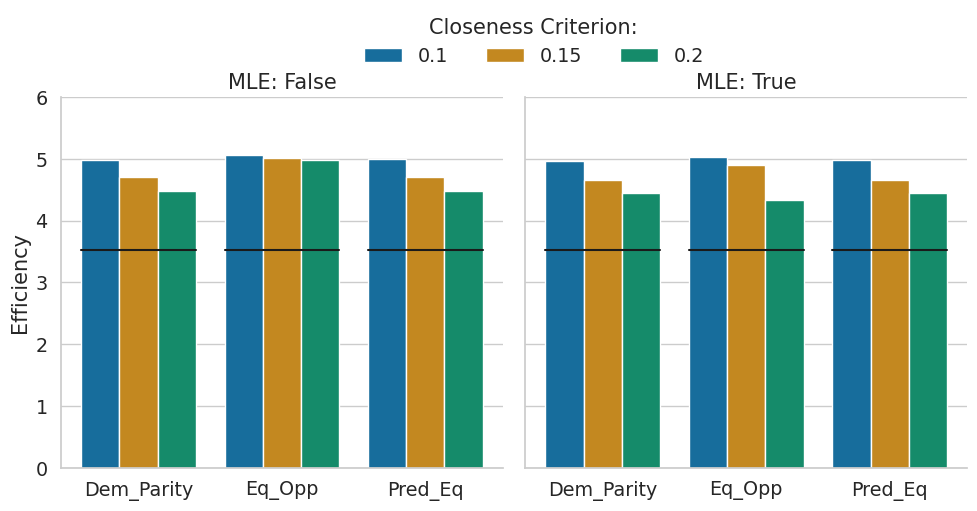

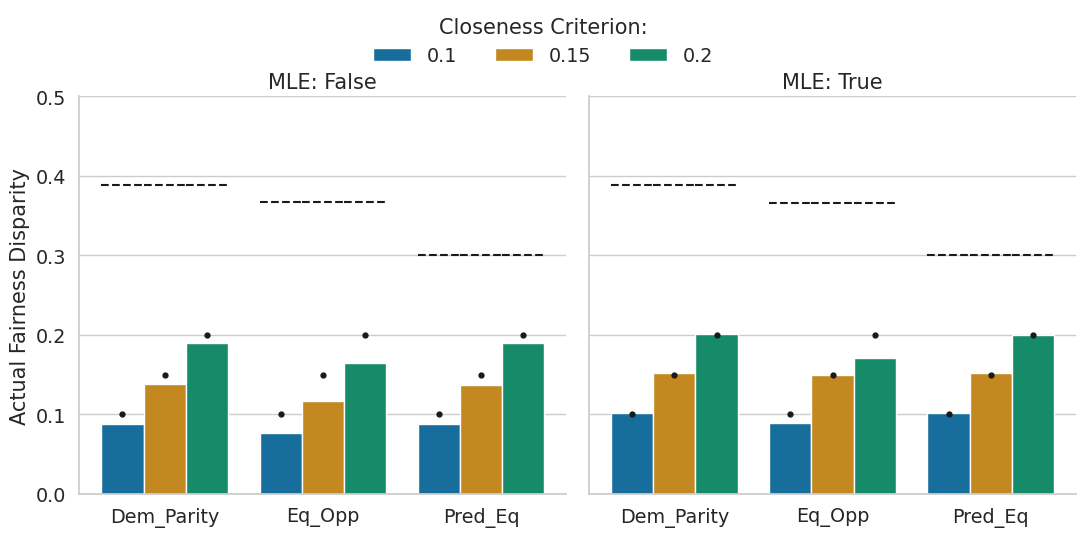

In [9]:
import matplotlib.pyplot as plt
import seaborn as sns

METRICS = list(map(lambda x: METRIC_MAP[x], ["Demographic_Parity", "Equal_Opportunity", "Predictive_Equality"]))

C = [0.1, 0.15, 0.2]
cp_method = "raps_rand_no_mod"
client_type = "continental_all"
eff_lim = 6
formulation = "Communication_Efficient"
USE_MLE = [False, True]
    
fdf = res_df[(res_df["dataset_sens_attrs"] == "ACSEducation") & (res_df["fairness_metric"].isin(METRICS)) & (res_df["cp_method"] == cp_method) & (res_df["client_type"] == client_type) & (res_df["formulation"] == formulation)]

# Plot efficiency
grid = sns.catplot(
    data=fdf[fdf["type"] == "ours"],
    x="fairness_metric",
    y="eff_mean",
    hue="c",
    hue_order=[str(c) for c in C],
    errorbar=None,
    col="use_mle",
    col_order=USE_MLE,
    kind="bar",
    order=METRICS,
    # 
    sharex=False,
)

grid.set(xlabel="")
grid.set(ylabel="Efficiency")
grid.set(ylim=(0, eff_lim))
for key, ax in grid.axes_dict.items():
  ax.set_title(f"MLE: {key}")
sns.move_legend(grid, "upper center", bbox_to_anchor=(0.5, 1.1), ncol=len(C))
grid.legend.set_title("Closeness Criterion:")

# Plot violation
grid2 = sns.catplot(
    data=fdf[fdf["type"] == "ours"],
    x="fairness_metric",
    y="violation_mean",
    hue="c",
    hue_order=[str(c) for c in C],
    errorbar=None,
    col="use_mle",
    col_order=USE_MLE,
    kind="bar",
    order=METRICS,
    # 
    sharex=False,
)
grid2.set(xlabel="")
grid2.set(ylabel="Actual Fairness Disparity")

grid2.set(ylim=(0, 0.5), yticks=[0, 0.1, 0.2, 0.3, 0.4, 0.5])
for key, ax in grid2.axes_dict.items():
  ax.set_title(f"MLE: {key}")
sns.move_legend(grid2, "upper center", bbox_to_anchor=(0.5, 1.1), ncol=len(C))
grid2.legend.set_title("Closeness Criterion:")

# Add the base FCP method lines and points

axes_eff = grid.axes.flatten() if isinstance(grid.axes, np.ndarray) else [grid.axes]
axes_viol = grid2.axes.flatten() if isinstance(grid2.axes, np.ndarray) else [grid2.axes]
# print("ACSEducation MLE comparison", use_mle, formulation)
axes_idx = 0
for i in range(len(USE_MLE)):
    base_cp_df = fdf[(fdf["type"] == "base")]
    if base_cp_df.empty:
        continue
    
    # Efficiency base line
    ax_eff = axes_eff[axes_idx]
    patches = ax_eff.patches

    for ix, a in enumerate(patches):
        x_start = a.get_x()
        width = a.get_width()
        if width == 0: 
            continue

        eff_mean = base_cp_df[(base_cp_df["fairness_metric"] == METRICS[ix % len(METRICS)]) & (base_cp_df["client_type"] == client_type) &  (base_cp_df["use_mle"] == USE_MLE[i])]["eff_mean"].mean()
        ax_eff.plot([x_start, x_start + width], [eff_mean] * 2, '-', c='k')

    # Violation base line and marker
    ax_viol = axes_viol[axes_idx]
    patches = ax_viol.patches

    for ix, a in enumerate(patches):
        x_start = a.get_x()
        width = a.get_width()
        if width == 0: 
            continue

        violation_mean = base_cp_df[(base_cp_df["fairness_metric"] == METRICS[ix % len(METRICS)]) & (base_cp_df["client_type"] == client_type) & (base_cp_df["use_mle"] == USE_MLE[i])]["violation_mean"].mean()
        ax_viol.plot([x_start, x_start + width], [violation_mean] * 2, '--', c='k')
        ax_viol.plot(x_start + width / 2, float(C[ix // len(METRICS)]), 'o', c='k', markersize=3.5)
    
    axes_idx += 1
    
plt.tight_layout()
form_slug = str(formulation).replace(" ", "_")
# Save the figure
grid.savefig(f"./figures/ACSEducation_mle_comparison_{form_slug}_efficiency.pdf", bbox_inches='tight')
grid2.savefig(f"./figures/ACSEducation_mle_comparison_{form_slug}_violation.pdf", bbox_inches='tight')

plt.show() 


Fitzpatrick formulation Communication_Efficient
Fitzpatrick formulation Enhanced_Privacy
Fitzpatrick formulation Hybrid


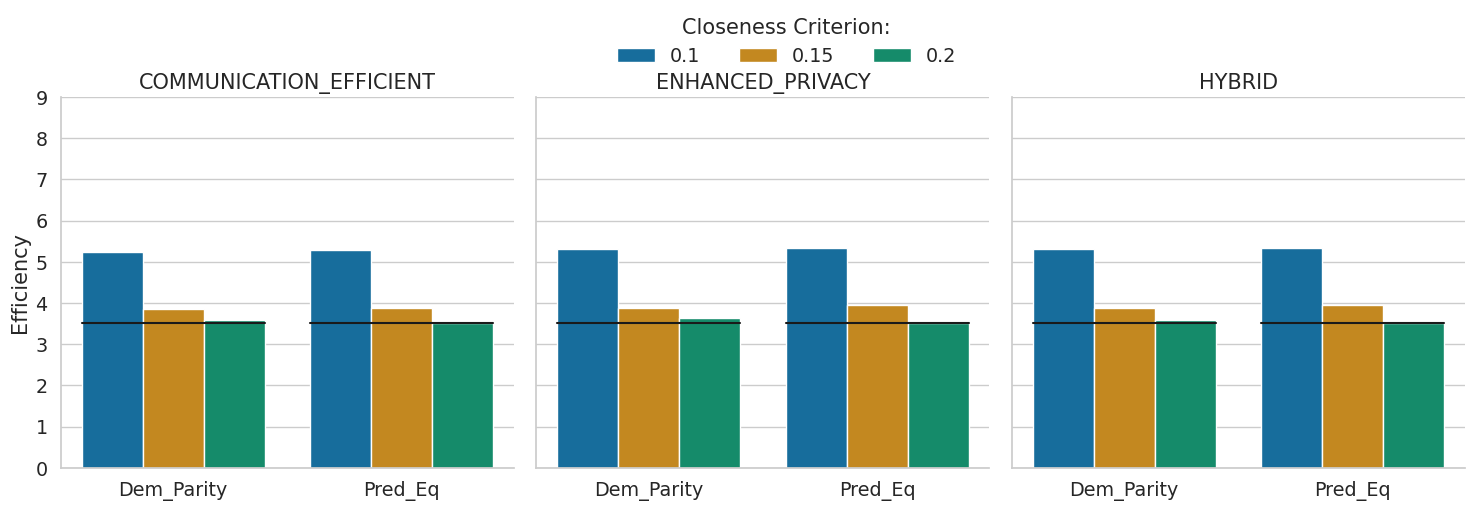

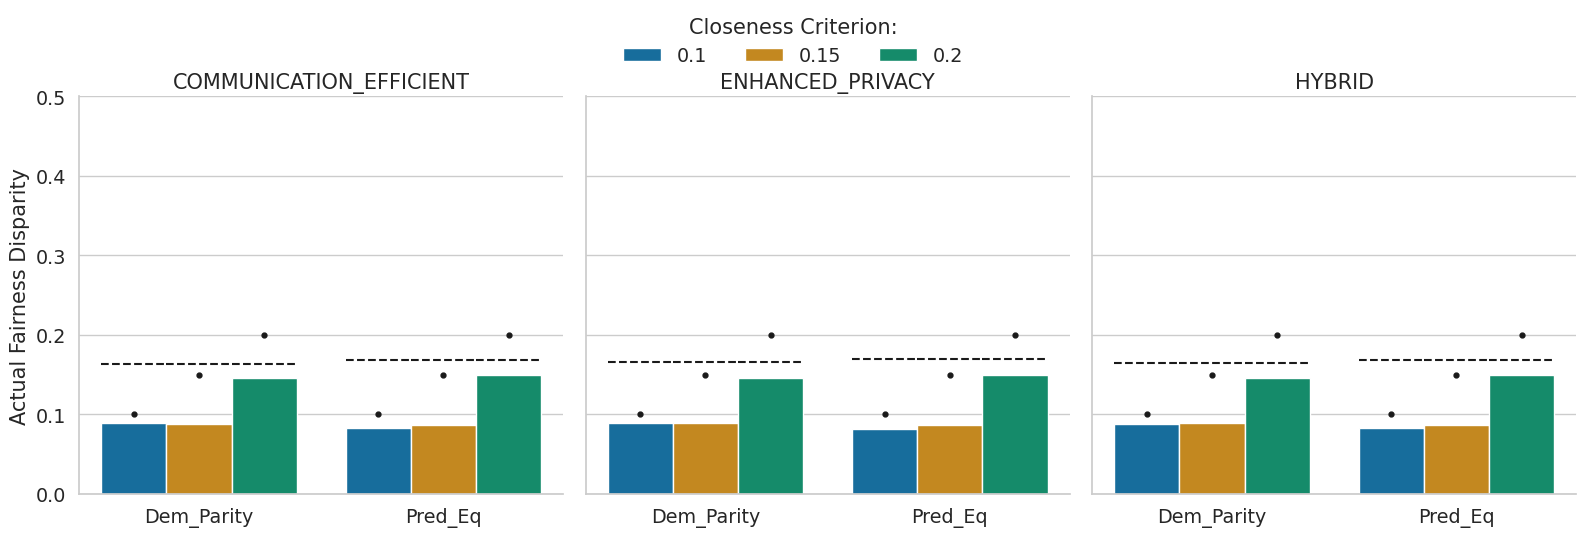

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

METRICS = list(map(lambda x: METRIC_MAP[x], ["Demographic_Parity", "Predictive_Equality"]))

C = [0.1, 0.15, 0.2]
cp_method = "raps_rand_no_mod"  # Table I.1 uses RAPS
client_type = "8_clients"
eff_lim = 9
FORMULATIONS = ["Communication_Efficient", "Enhanced_Privacy", "Hybrid"]
use_mle = False

fdf = res_df[(res_df["dataset_sens_attrs"] == "Fitzpatrick") & (res_df["fairness_metric"].isin(METRICS)) & (res_df["cp_method"] == cp_method) & (res_df["client_type"] == client_type) & (res_df["use_mle"] == use_mle)]

# Plot efficiency
grid = sns.catplot(
    data=fdf[fdf["type"] == "ours"],
    x="fairness_metric",
    y="eff_mean",
    hue="c",
    hue_order=[str(c) for c in C],
    errorbar=None,
    col="formulation",
    col_order=FORMULATIONS,
    kind="bar",
    order=METRICS,
    
    sharex=False,
)

grid.set(xlabel="")
grid.set(ylabel="Efficiency")
grid.set(ylim=(0, eff_lim))
for key, ax in grid.axes_dict.items():
  ax.set_title(key.upper())
sns.move_legend(grid, "upper center", bbox_to_anchor=(0.5, 1.1), ncol=len(C))
grid.legend.set_title("Closeness Criterion:")

# Plot violation
grid2 = sns.catplot(
    data=fdf[fdf["type"] == "ours"],
    x="fairness_metric",
    y="violation_mean",
    hue="c",
    hue_order=[str(c) for c in C],
    errorbar=None,
    col="formulation",
    col_order=FORMULATIONS,
    kind="bar",
    order=METRICS,
    
    sharex=False,
)
grid2.set(xlabel="")
grid2.set(ylabel="Actual Fairness Disparity")

grid2.set(ylim=(0, 0.5), yticks=[0, 0.1, 0.2, 0.3, 0.4, 0.5])
for key, ax in grid2.axes_dict.items():
  ax.set_title(key.upper())
sns.move_legend(grid2, "upper center", bbox_to_anchor=(0.5, 1.1), ncol=len(C))
grid2.legend.set_title("Closeness Criterion:")

# Add the base FCP method lines and points

axes_eff = grid.axes.flatten() if isinstance(grid.axes, np.ndarray) else [grid.axes]
axes_viol = grid2.axes.flatten() if isinstance(grid2.axes, np.ndarray) else [grid2.axes]
axes_idx = 0
for i in range(len(FORMULATIONS)):
    print("Fitzpatrick formulation", FORMULATIONS[i])

    base_cp_df = fdf[(fdf["type"] == "base")]
    if base_cp_df.empty:
        continue
    
    # Efficiency base line
    ax_eff = axes_eff[axes_idx]
    patches = ax_eff.patches

    for ix, a in enumerate(patches):
        x_start = a.get_x()
        width = a.get_width()
        if width == 0: 
            continue

        eff_mean = base_cp_df[(base_cp_df["fairness_metric"] == METRICS[ix % len(METRICS)]) & (base_cp_df["client_type"] == client_type) & (base_cp_df["formulation"] == FORMULATIONS[i])]["eff_mean"].mean()
        ax_eff.plot([x_start, x_start + width], [eff_mean] * 2, '-', c='k')

    # Violation base line and marker
    ax_viol = axes_viol[axes_idx]
    patches = ax_viol.patches

    for ix, a in enumerate(patches):
        x_start = a.get_x()
        width = a.get_width()
        if width == 0: 
            continue
            
        violation_mean = base_cp_df[(base_cp_df["fairness_metric"] == METRICS[ix % len(METRICS)]) & (base_cp_df["client_type"] == client_type) & (base_cp_df["formulation"] == FORMULATIONS[i])]["violation_mean"].mean()
        ax_viol.plot([x_start, x_start + width], [violation_mean] * 2, '--', c='k')
        ax_viol.plot(x_start + width / 2, float(C[ix // len(METRICS)]), 'o', c='k', markersize=3.5)
    
    axes_idx += 1
    
plt.tight_layout()
form_slug = str(FORMULATIONS[i]).replace(" ", "_")
# Save the figure
grid.savefig(f"./figures/Fitzpatrick_formulation_comparison_{client_type}_efficiency.pdf", bbox_inches='tight')
grid2.savefig(f"./figures/Fitzpatrick_formulation_comparison_{client_type}_violation.pdf", bbox_inches='tight')

plt.show() 


## Camera-ready tables
Means over seeds 0-2. Each table is written to `./tables/<name>.csv` and `./tables/<name>.tex`.

In [11]:
import glob
os.makedirs("./tables", exist_ok=True)

def _num(s):
    return pd.to_numeric(s.astype(str).str.replace(r"tensor\(|\)", "", regex=True), errors="coerce")

def load_trials(path):
    """One trials CSV with numeric metrics and a protocol label."""
    d = pd.read_csv(path, index_col=0)
    for col in ["efficiency", "violation", "coverage", "base_efficiency", "base_violation", "base_coverage"]:
        d[col] = _num(d[col])
    fc = d.filter(regex=r"^client_formulation_\d+$")
    d["formulation"] = np.where((fc.fillna(0) == 0).all(axis=1), "CE",
                       np.where((fc.fillna(1) == 1).all(axis=1), "EP", "HY"))
    for col, default in [("use_descent", True), ("use_group_info", False), ("num_opt_rounds", 100)]:
        d[col] = d[col].fillna(default) if col in d else default
    d["use_mle"] = d["use_mle"].astype(str) == "True"
    return d

def ev(df, base=False, digits=3):
    """'efficiency / violation' averaged over seeds, plus a seed-count check."""
    pre = "base_" if base else ""
    assert df["seed"].nunique() == 3 and len(df) == 3, f"expected 3 seeds, got {sorted(df['seed'])}"
    return f"{df[pre + 'efficiency'].mean():.{digits}f} / {df[pre + 'violation'].mean():.{digits}f}"

def save(name, table):
    table.to_csv(f"./tables/{name}.csv")
    table.to_latex(f"./tables/{name}.tex")
    print(f"== {name}"); display(table)

S = "split_0.3_0.2"
CS = [0.1, 0.15, 0.2]
T = lambda *parts: os.path.join("fairness_trials", *parts)
std = lambda d: d[(d["use_descent"] == True) & (d["use_group_info"] == False) & (d["num_opt_rounds"] == 100)]

# Table 2: Fitzpatrick, RAPS, communication-efficient, K clients
rows = {}
for k in [1, 2, 4, 8]:
    for m in ["Demographic_Parity", "Predictive_Equality"]:
        d = std(load_trials(T("Fitzpatrick", f"{k}_clients", S, m, "raps_rand_no_mod.csv")))
        d = d[(d.formulation == "CE") & ~d.use_mle]
        for c in CS:
            dc = d[d.c == c]
            rows[(f"c={c}", METRIC_MAP[m])] = rows.get((f"c={c}", METRIC_MAP[m]), {}) | {
                (f"{k} client(s)", "Base"): ev(dc, base=True), (f"{k} client(s)", "Ours"): ev(dc)}
save("table2_fitzpatrick_clients", pd.DataFrame(rows).T)

# Table 3: ACSEducation continental_small, RAPS, Dem. Parity: classwise vs (group, class)-wise efficiency
base = T("ACSEducation", "continental_small", S, "Demographic_Parity")
cls = std(load_trials(os.path.join(base, "raps_rand_no_mod.csv")))
cls = cls[(cls.formulation == "CE") & ~cls.use_mle]
grp = load_trials(os.path.join(base, "group_aware", "raps_rand_no_mod.csv"))
grp = grp[(grp.formulation == "CE") & ~grp.use_mle]
t3 = pd.DataFrame({"Classwise": [cls[cls.c == c].efficiency.mean() for c in CS],
                   "(Group, Class)-wise": [grp[grp.c == c].efficiency.mean() for c in CS]}, index=CS).round(3)
assert all(cls[cls.c == c].seed.nunique() == 3 and grp[grp.c == c].seed.nunique() == 3 for c in CS)
save("table3_group_information", t3)

# Table 4: robustness, ACSIncome continental_large, RAPS, Dem. Parity
p = lambda root: os.path.join(root, "ACSIncome", "continental_large", S, "Demographic_Parity", "raps_rand_no_mod.csv")
noshift = std(load_trials(p("fairness_trials"))); noshift = noshift[(noshift.formulation == "CE") & ~noshift.use_mle]
gauss = load_trials(p("fairness_trials_shift_het"))  # Gaussian noise + 25% shuffle
shift = load_trials(p("fairness_trials_shift"))
cols = {"No Shift (FedCF)": noshift, "Gaussian Noise": gauss[gauss.distribution_shift_gaussian_noise == True],
        # Shuffle runs on 25% of clients live with the other partial-client shift in _shift_het.
        "Shuffle Group (25%)": gauss[gauss.distribution_shift_shuffle_group == True],
        "Subsample": shift[shift.distribution_shift_subsample == True],
        "Swap Extreme Groups": shift[shift.distribution_shift_swap_extreme_groups == True]}
save("table4_robustness", pd.DataFrame({k: [ev(v[v.c == c], digits=4) for c in CS] for k, v in cols.items()}, index=CS))

# Table D.1: descent vs iterative, ACSIncome small, RAPS, Dem. Parity
d = load_trials(T("ACSIncome", "small", S, "Demographic_Parity", "raps_rand_no_mod.csv"))
d = d[(d.formulation == "CE") & ~d.use_mle & (d.use_group_info == False)]
variants = {"Descent-Based (100)": d[(d.use_descent == True) & (d.num_opt_rounds == 100)],
            "Iterative (100)": d[(d.use_descent == False) & (d.num_opt_rounds == 100)],
            "Iterative (1000)": d[(d.use_descent == False) & (d.num_opt_rounds == 1000)]}
save("tableD1_descent_vs_iterative", pd.DataFrame({f"c={c}": {k: ev(v[v.c == c]) for k, v in variants.items()} for c in CS}))

# Tables I.1 / I.2: protocols (RAPS)
for name, ds, part in [("tableI1_fitzpatrick_protocols", "Fitzpatrick", "8_clients"),
                       ("tableI2_acsincome_protocols", "ACSIncome", "continental_all")]:
    rows = {}
    for form, label in [("EP", "Enhanced Privacy"), ("HY", "Hybrid (50-50)"), ("CE", "Communication Efficient")]:
        for m in ["Demographic_Parity", "Predictive_Equality"]:
            d = std(load_trials(T(ds, part, S, m, "raps_rand_no_mod.csv")))
            d = d[(d.formulation == form) & ~d.use_mle]
            rows[(label, METRIC_MAP[m])] = {(f"c={c}", w): ev(d[d.c == c], base=(w == "Base")) for c in CS for w in ["Base", "Ours"]}
    save(name, pd.DataFrame(rows).T)

# Table I.3: average bytes sent per client, ACSIncome continental_large
d = load_trials(p("fairness_trials_bytes"))
bcols = sorted(d.filter(regex=r"^avg_bytes_sent_client_\d+$").columns, key=lambda x: int(x.rsplit("_", 1)[1]))
t = pd.DataFrame({lab: d[d.formulation == f][bcols].mean().values for f, lab in [("CE", "Communication Efficient"), ("EP", "Enhanced Privacy")]},
                 index=[f"Client {i}" for i in range(len(bcols))])
t.loc["Average"] = t.mean()
save("tableI3_bytes", t.round(1))

# Table L.1: marginal coverage, Dem. Parity
rows = {}
for label, path in [("Pokec-{n,z} (DAPS)", T("Pokec_region_gender", "2_clients", S, "Demographic_Parity", "daps.csv")),
                    ("Fitzpatrick (RAPS)", T("Fitzpatrick", "8_clients", S, "Demographic_Parity", "raps_rand_no_mod.csv")),
                    ("ACSEducation (RAPS)", T("ACSEducation", "continental_small", S, "Demographic_Parity", "raps_rand_no_mod.csv"))]:
    d = std(load_trials(path)); d = d[(d.formulation == "CE") & ~d.use_mle]
    for c in CS:
        dc = d[d.c == c]; assert dc.seed.nunique() == 3
        rows[(label, c)] = {"Base (FedCP)": round(dc.base_coverage.mean(), 3), "FedCF": round(dc.coverage.mean(), 3)}
save("tableL1_coverage", pd.DataFrame(rows))



== table2_fitzpatrick_clients


1 client(s)                   2 client(s)                 \
                            Base           Ours           Base           Ours   
c=0.1  Dem_Parity  2.356 / 0.151  3.647 / 0.103  2.542 / 0.161  4.122 / 0.153   
c=0.15 Dem_Parity  2.356 / 0.151  2.356 / 0.151  2.542 / 0.161  2.775 / 0.161   
c=0.2  Dem_Parity  2.356 / 0.151  2.356 / 0.151  2.550 / 0.162  2.550 / 0.162   
c=0.1  Pred_Eq     2.356 / 0.111  3.647 / 0.109  2.543 / 0.177  4.139 / 0.177   
c=0.15 Pred_Eq     2.356 / 0.111  2.356 / 0.111  2.543 / 0.177  2.778 / 0.177   
c=0.2  Pred_Eq     2.356 / 0.111  2.356 / 0.111  2.543 / 0.177  2.543 / 0.177   

                     4 client(s)                   8 client(s)                 
                            Base           Ours           Base           Ours  
c=0.1  Dem_Parity  2.846 / 0.294  4.684 / 0.099  3.504 / 0.164  5.241 / 0.089  
c=0.15 Dem_Parity  2.840 / 0.294  3.349 / 0.117  3.505 / 0.164  3.863 / 0.087  
c=0.2  Dem_Parity  2.841 / 0.292  3.259 / 0.164  3.504 / 0.162  3.586 / 0.146  
c=0.1  Pred_Eq     2.841 / 0.288  4.564 / 0.102  3.502 / 0.169  5.293 / 0.083  
c=0.15 Pred_Eq     2.839 / 0.288  3.331 / 0.114  3.500 / 0.168  3.870 / 0.087  
c=0.2  Pred_Eq     2.837 / 0.287  3.256 / 0.167  3.503 / 0.169  3.525 / 0.150

== table3_group_information


,Classwise,"(Group, Class)-wise"
0.10,5.010,4.779
0.15,4.826,4.439
0.20,3.982,3.957


== table4_robustness


,No Shift (FedCF),Gaussian Noise,Shuffle Group (25%),Subsample,Swap Extreme Groups
0.10,2.9791 / 0.1051,2.8696 / 0.1345,2.9785 / 0.0850,2.9599 / 0.1700,2.9788 / 0.1051
0.15,2.7163 / 0.1553,2.6754 / 0.1630,2.7160 / 0.1211,2.7661 / 0.2273,2.7162 / 0.1553
0.20,2.5846 / 0.2049,2.5664 / 0.1918,2.5847 / 0.1535,2.5982 / 0.3781,2.5841 / 0.2049


... (6 outputs left out)

== tableI3_bytes


,Communication Efficient,Enhanced Privacy
Client 0,619.5,885.2
Client 1,612.8,896.5
Client 2,605.0,881.1
Client 3,609.0,907.8
Client 4,603.2,896.5
Client 5,636.8,917.8
Client 6,610.4,904.8
Client 7,622.5,888.4
Average,614.9,897.2


== tableL1_coverage


Pokec-{n,z} (DAPS)               Fitzpatrick (RAPS)         \
                           0.10   0.15   0.20               0.10   0.15   
Base (FedCP)              0.892  0.892  0.892              0.895  0.895   
FedCF                     0.898  0.894  0.892              0.927  0.909   

                    ACSEducation (RAPS)                
               0.20                0.10   0.15   0.20  
Base (FedCP)  0.895               0.932  0.932  0.932  
FedCF         0.899               0.977  0.973  0.952

In [12]:
# Figure L.4 (new): elbow curve, ACSIncome continental_large, RAPS, Dem. Parity
import subprocess, sys
subprocess.run([sys.executable, "plot_elbow_curve.py",
                "Dem. Parity=fairness_trials/ACSIncome/continental_large/split_0.3_0.2/Demographic_Parity/raps_rand_no_mod.csv",
                "--query", "use_mle == False",
                "--out", "figures/elbow_acsincome_continental_large.pdf"], check=True)


Dem. Parity: elbow at c = 0.125
      efficiency violation
            mean      mean
c                         
0.025     3.3241    0.0255
0.050     3.2395    0.0517
0.075     3.0995    0.0769
0.100     2.9791    0.1051
0.125     2.7742    0.1338
0.150     2.7163    0.1553
0.175     2.6568    0.1805
0.200     2.5846    0.2049
0.250     2.4674    0.2603
0.300     2.3818    0.3143 

Saved figures/elbow_acsincome_continental_large.pdf


CompletedProcess(args=['python3', 'plot_elbow_curve.py', 'Dem. Parity=fairness_trials/ACSIncome/continental_large/split_0.3_0.2/Demographic_Parity/raps_rand_no_mod.csv', '--query', 'use_mle == False', '--out', 'figures/elbow_acsincome_continental_large.pdf'], returncode=0)